## [LAB-08] [PBT] 탐색적 데이터 분석

### 02_단변량 분석

### #01 준비작업

#### 1. 이전 분석 내용 가져오기

- 데이터 로드, 기초 통계량 가져오기 증의 반복적인 작업은 별도의 ipynb 파일에 구현해두고 Jupyter Magic Command로 불러올 수 있다.
    - 다른 ipynb 파일의 소스코드를 이 위치에 복붙하는 효과가 있다.
    - 가져온 ipynb 파일의 import 내용이나 변수들이 모두 유지된다.

In [5]:
%%capture cap

%run "./01_EDA 준비하기.ipynb"

#### 2. 불러온 내용 확인

In [6]:
print("종속변수 :", target)
print("종속변수 유형 :" + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

display(df.head())
display(desc.head())
display(cat_desc.head())

종속변수 : MEDV
종속변수 유형 :연속형
명목형   : ['CHAS']
연속형   : ['CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.006,18.000,2.310,0,0.538,6.575,65.200,4.090,1,296,15.300,396.900,4.980,24.000
1,0.027,0.000,7.070,0,0.469,6.421,78.900,4.967,2,242,17.800,396.900,9.140,21.600
2,0.027,0.000,7.070,0,0.469,7.185,61.100,4.967,2,242,17.800,392.830,4.030,34.700
3,0.032,0.000,2.180,0,0.458,6.998,45.800,6.062,3,222,18.700,394.630,2.940,33.400
4,0.069,0.000,2.180,0,0.458,7.147,54.200,6.062,3,222,18.700,396.900,5.330,36.200


,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
CRIM,506.000,3.614,8.602,0.006,0.082,0.257,3.677,88.976,13.087,large_diff,3.595,9.070,-5.311,66,0.130,0,0.000,66,0.130,5.223,right tail,37.131,leptokurtic,log
ZN,506.000,11.364,23.322,0.000,0.000,0.000,12.500,100.000,inf,large_diff,12.500,31.250,-18.750,68,0.134,0,0.000,68,0.134,2.226,right tail,4.032,leptokurtic,log1p
INDUS,506.000,11.137,6.860,0.460,5.190,9.690,18.100,27.740,0.149,diff,12.910,37.465,-14.175,0,0.000,0,0.000,0,0.000,0.295,symmetric,-1.234,platykurtic,none
NOX,506.000,0.555,0.116,0.385,0.449,0.538,0.624,0.871,0.031,similar,0.175,0.886,0.187,0,0.000,0,0.000,0,0.000,0.729,right tail,-0.065,platykurtic,none
RM,506.000,6.285,0.703,3.561,5.885,6.208,6.623,8.780,0.012,similar,0.738,7.731,4.778,22,0.043,8,0.016,30,0.059,0.404,symmetric,1.892,leptokurtic,none


,CHAS
count,506
unique,2
top,0
freq,471


#### 3. 라이브러리 참조하기

In [7]:
from helpers import *

### #02 종속변수의 다변량 분석

#### 1. 연속형 변수에 대한 분석 수행

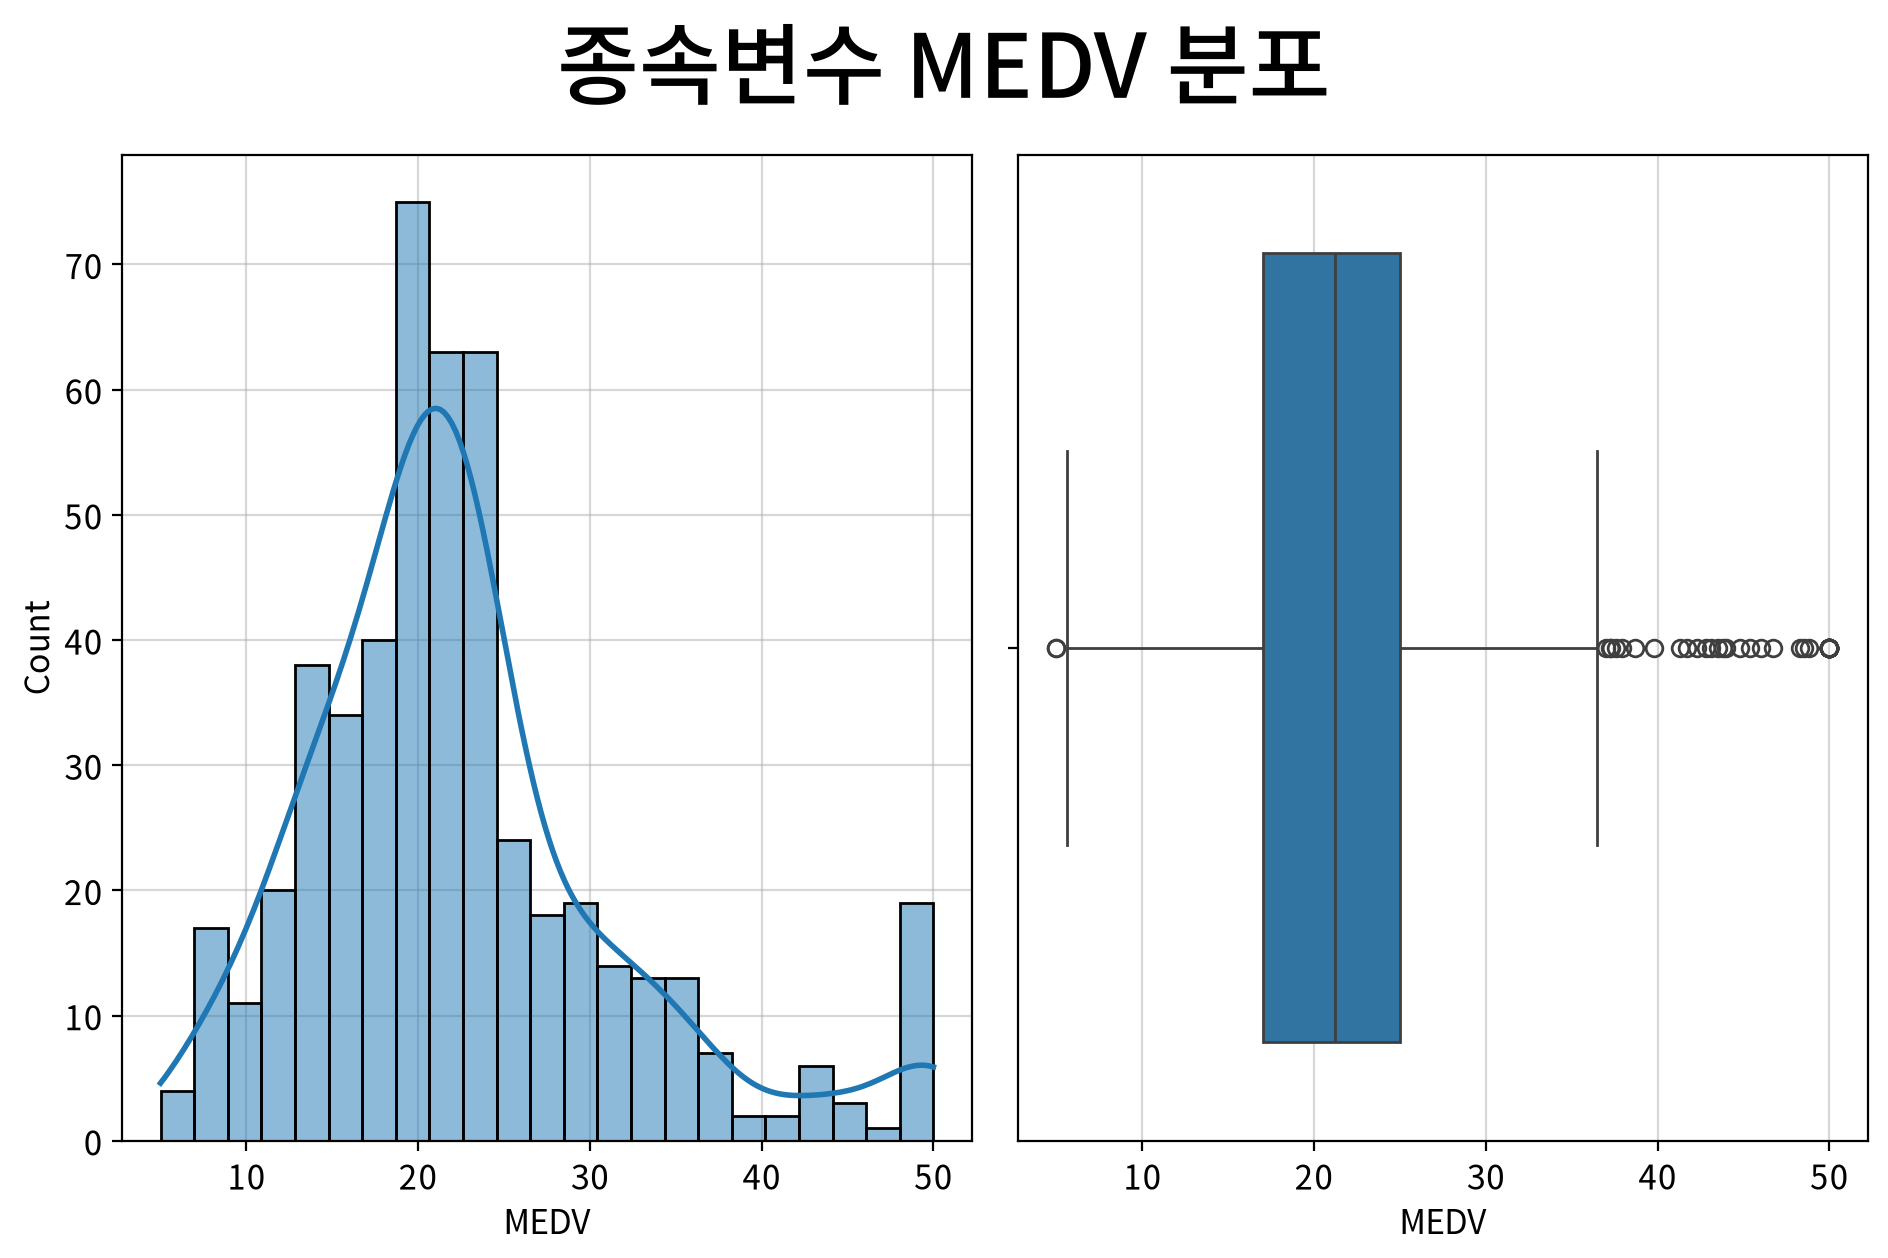

,MEDV
count,506.000
mean,22.533
std,9.197
min,5.000
25%,17.025
50%,21.200
75%,25.000
max,50.000
rel_diff,0.063
rdiff_flag,similar


In [8]:
# 1행 2열 서브플롯 구성
# -> 그래프 크기는 서브플롯 중 하나의 크기 (전체 크기는 가로 960 x 2가 됨)
fig, ax = my_plot.init(rows=1, cols=2,
                       title=f"종속변수 {target} 분포", width=960, height=640)
my_plot.histplot(data=df, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df, x=target, ax=ax[1])
my_plot.show()

# 연속형 변수 기술통계량에서 종속변수에 대한 부분만 추출
desc[desc.index == target].T

| 점검 항목     | MEDV 관찰 내용                 |
| --------- | -------------------------- |
| 분포 모양(왜도) | 오른쪽으로 치우침(우편향, skew ≈ 1.1) |
| 봉우리 수     | 단봉 — 오른쪽 끝(50)에 인위적 군집     |
| 이상치       | 위쪽 수염 밖에 점 존재(상위 약 8%)     |
| 이산점(군집)   | 50에 값이 뭉침 = 상한 처리(천장효과)    |

### #03 독립변수의 단변량 분석

#### 1. 연속형 독립변수

- 각 변수를 분포 모양(왜도), 봉우리 수, 이상치(박스플롯 점), 이산점(군집) 관점에서 점검하여\
"그대로 검정/모델에 넣어도 되는가?"를 판단한다.

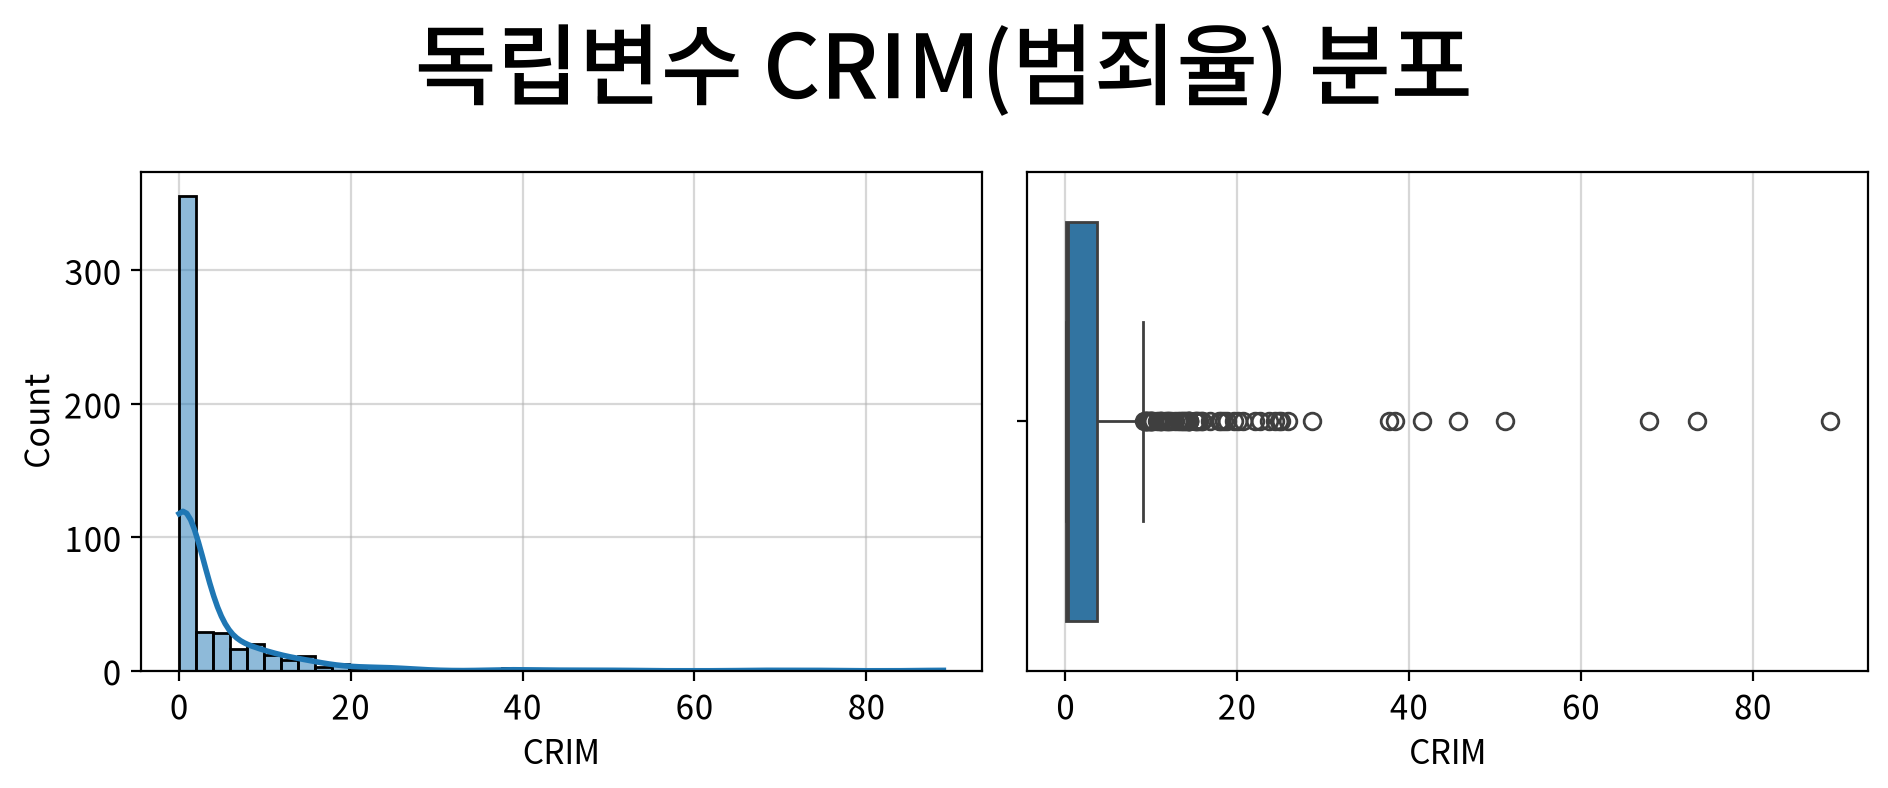

,CRIM
count,506.000
mean,3.614
std,8.602
min,0.006
25%,0.082
50%,0.257
75%,3.677
max,88.976
rel_diff,13.087
rdiff_flag,large_diff


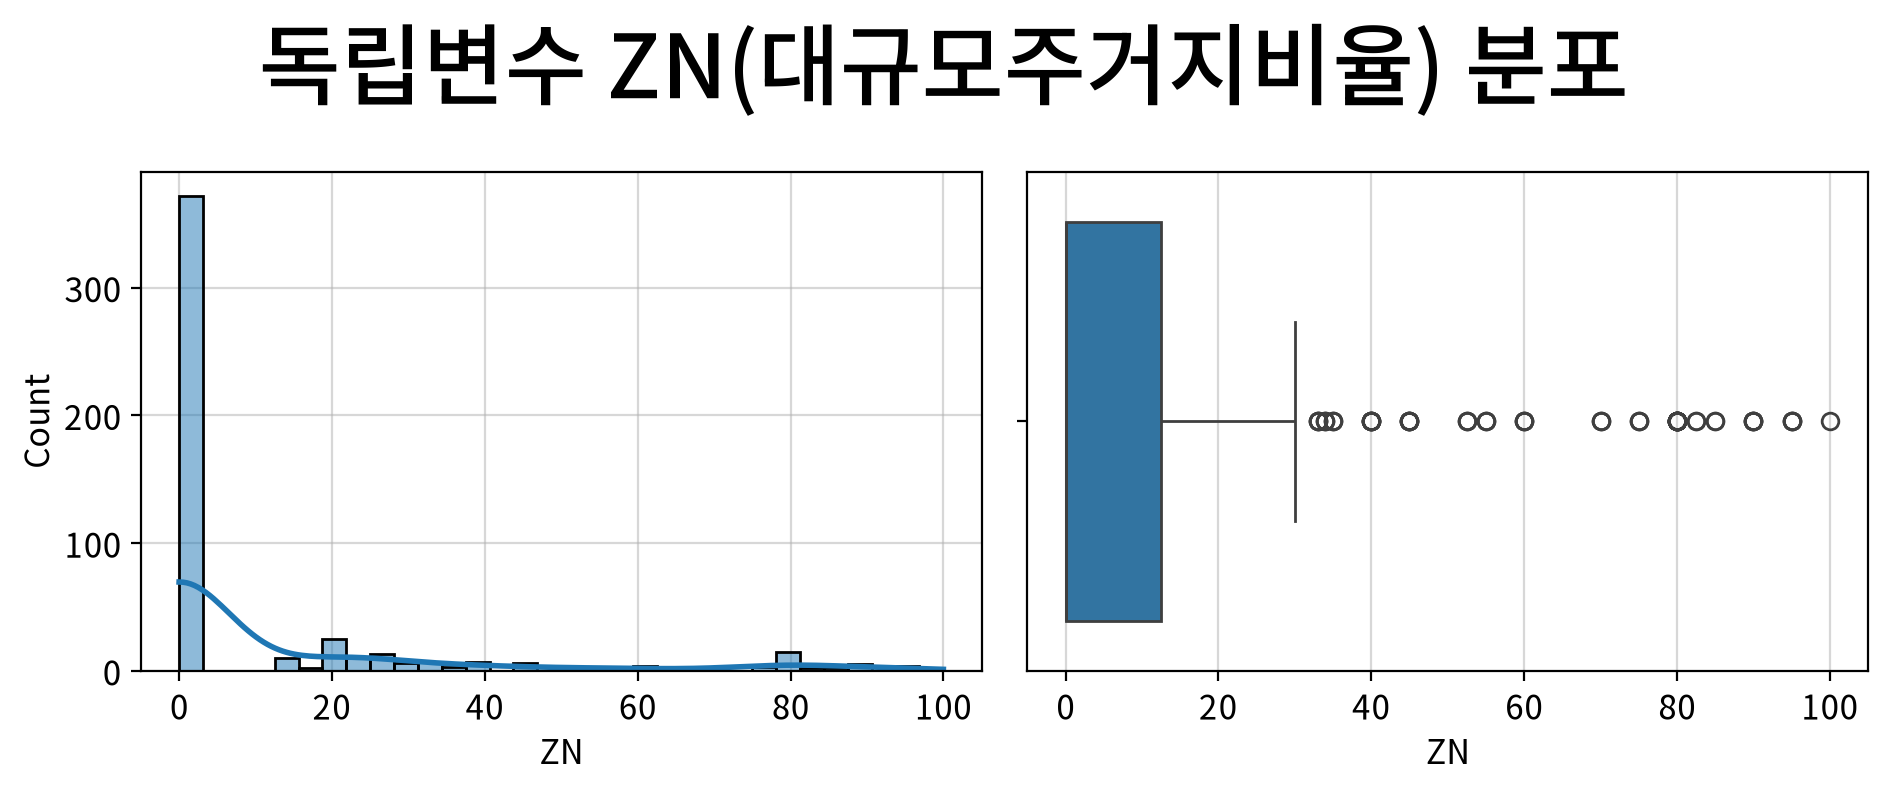

,ZN
count,506.000
mean,11.364
std,23.322
min,0.000
25%,0.000
50%,0.000
75%,12.500
max,100.000
rel_diff,inf
rdiff_flag,large_diff


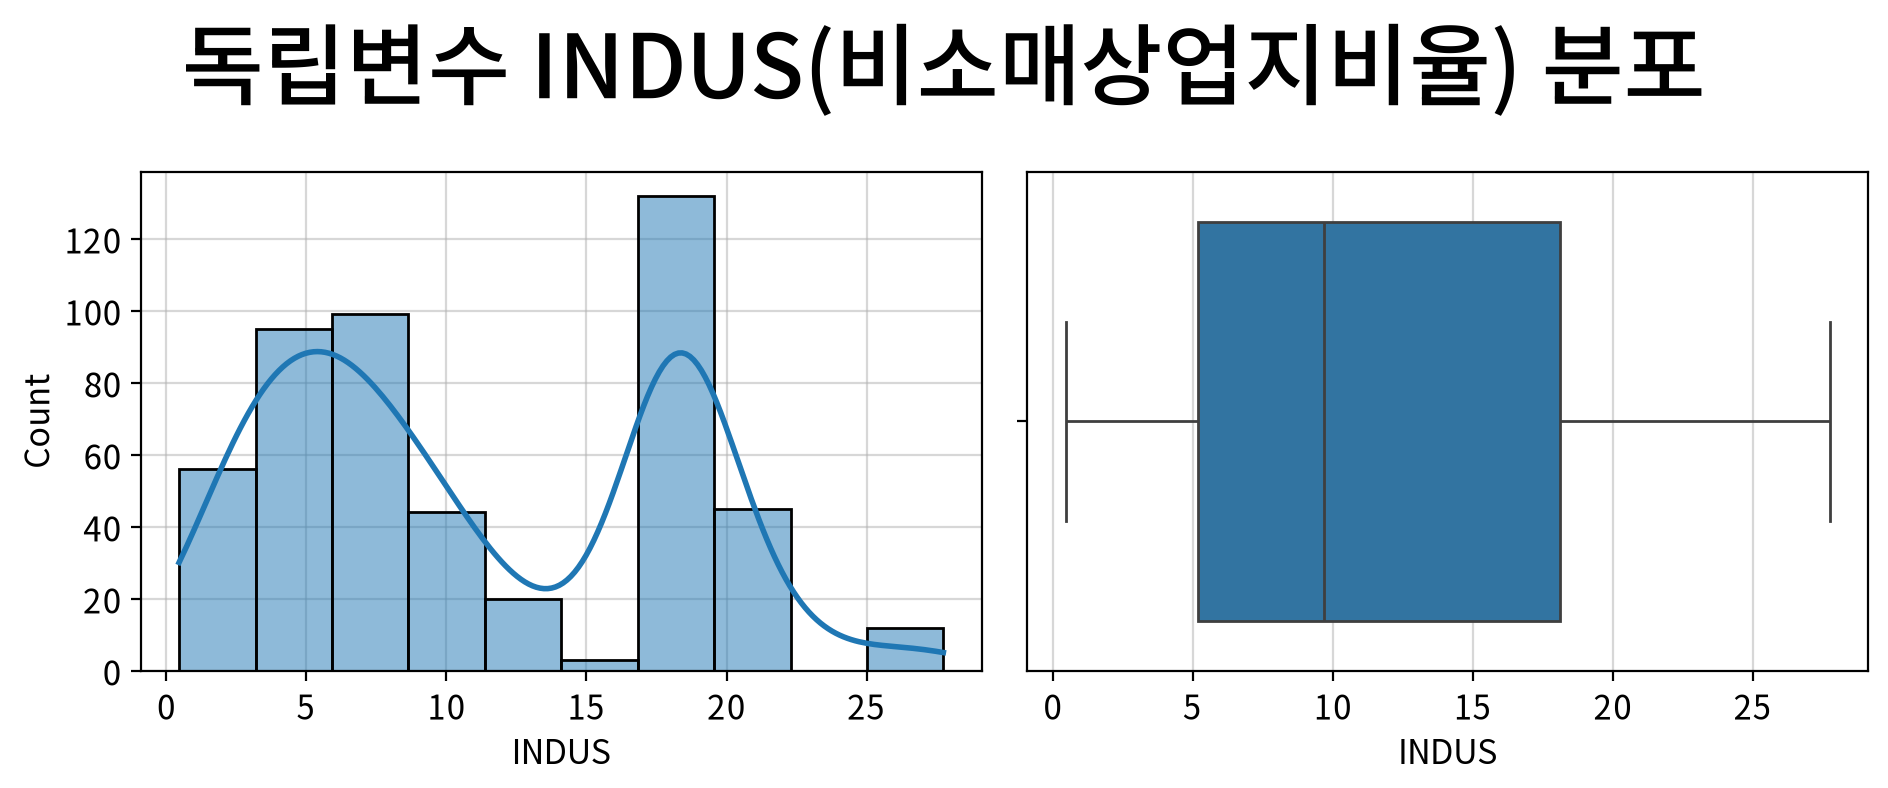

,INDUS
count,506.000
mean,11.137
std,6.860
min,0.460
25%,5.190
50%,9.690
75%,18.100
max,27.740
rel_diff,0.149
rdiff_flag,diff


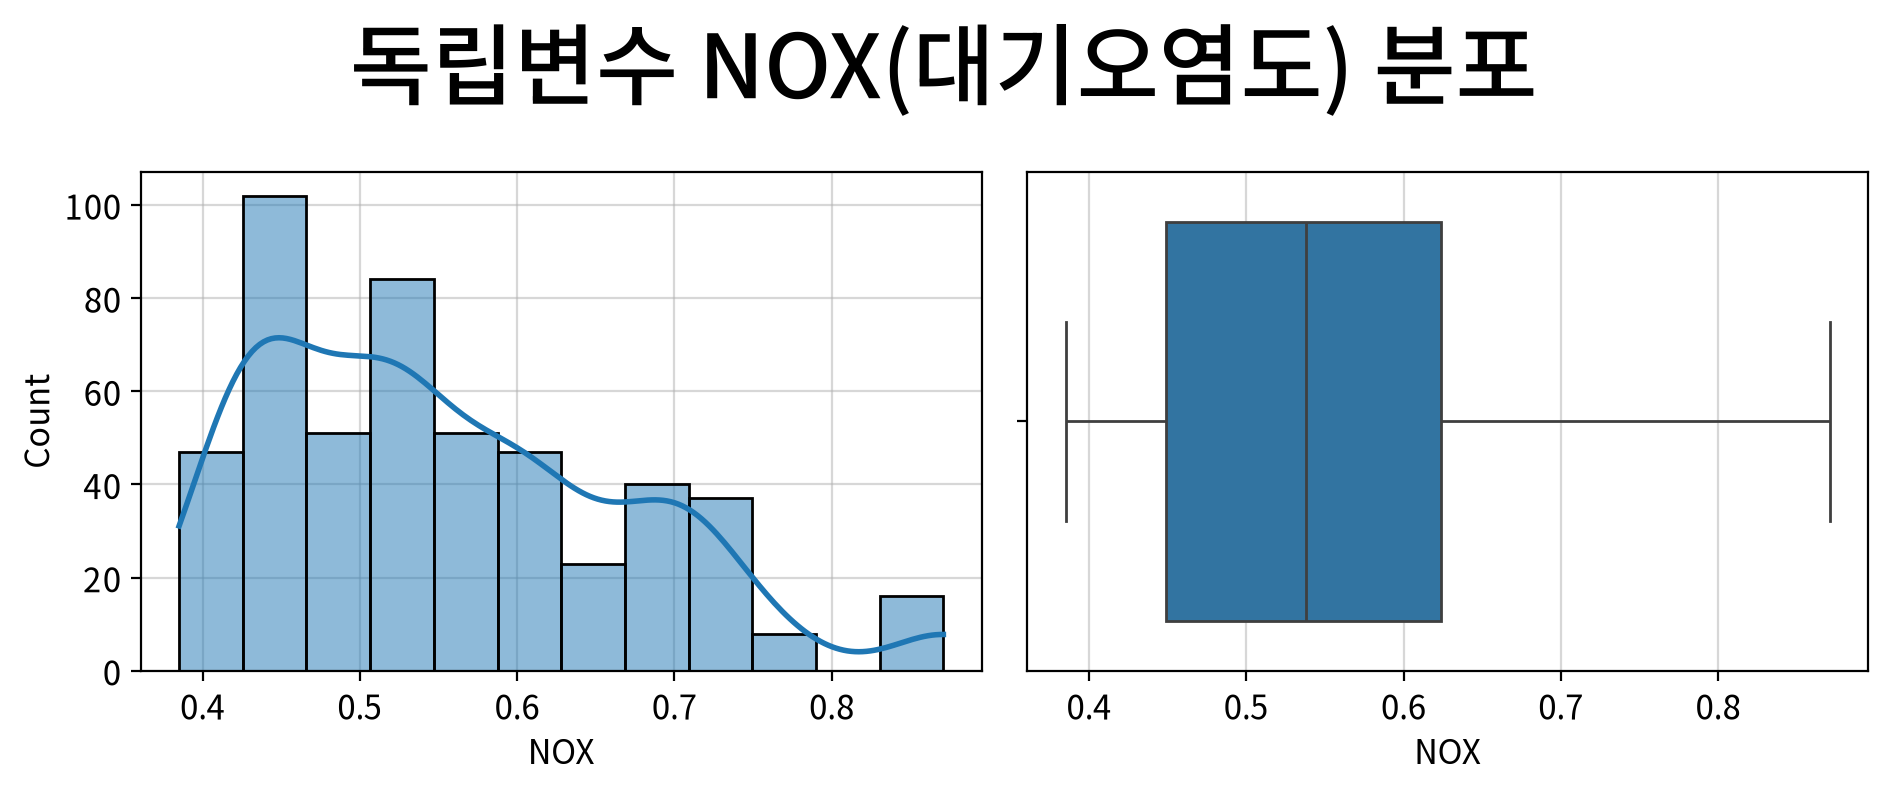

,NOX
count,506.000
mean,0.555
std,0.116
min,0.385
25%,0.449
50%,0.538
75%,0.624
max,0.871
rel_diff,0.031
rdiff_flag,similar


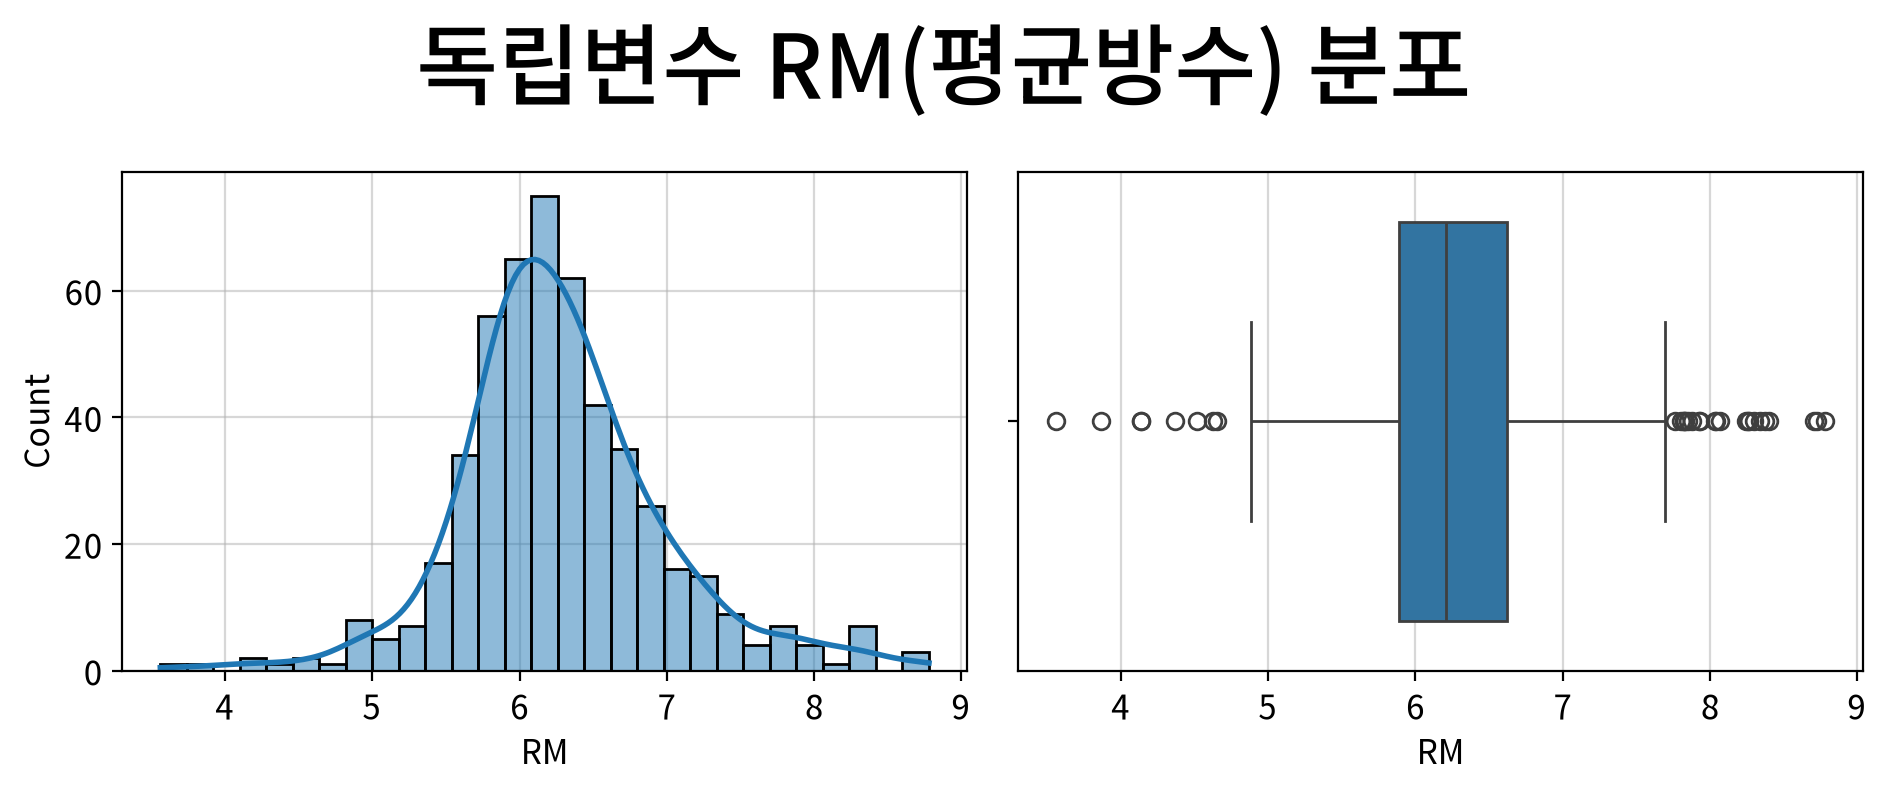

,RM
count,506.000
mean,6.285
std,0.703
min,3.561
25%,5.885
50%,6.208
75%,6.623
max,8.780
rel_diff,0.012
rdiff_flag,similar


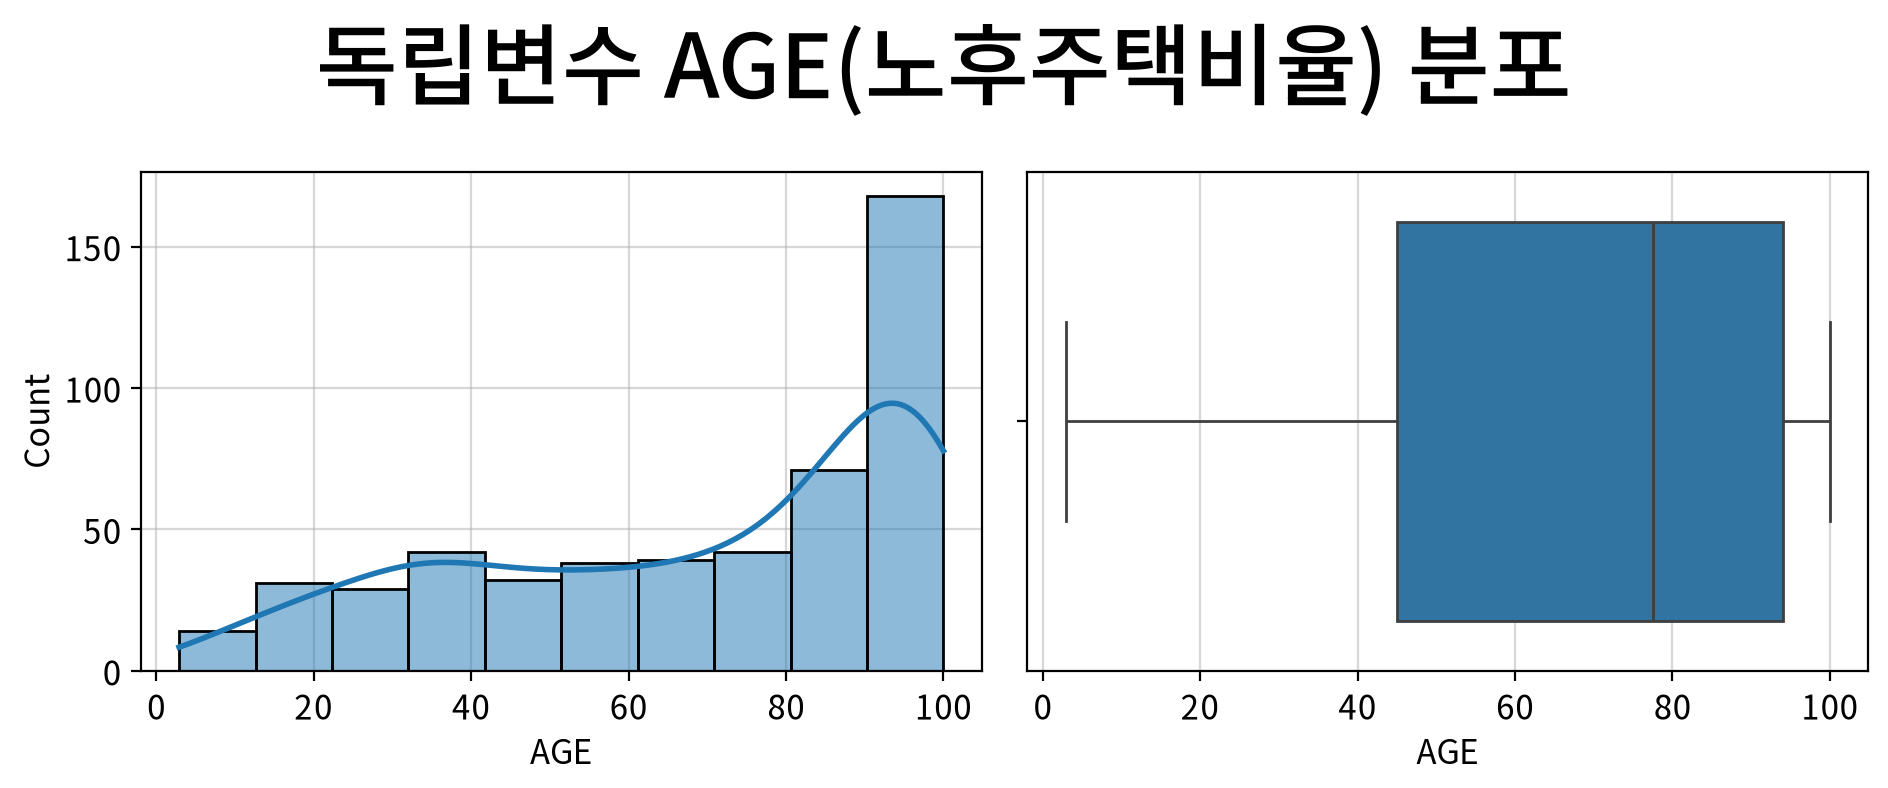

,AGE
count,506.000
mean,68.575
std,28.149
min,2.900
25%,45.025
50%,77.500
75%,94.075
max,100.000
rel_diff,0.115
rdiff_flag,diff


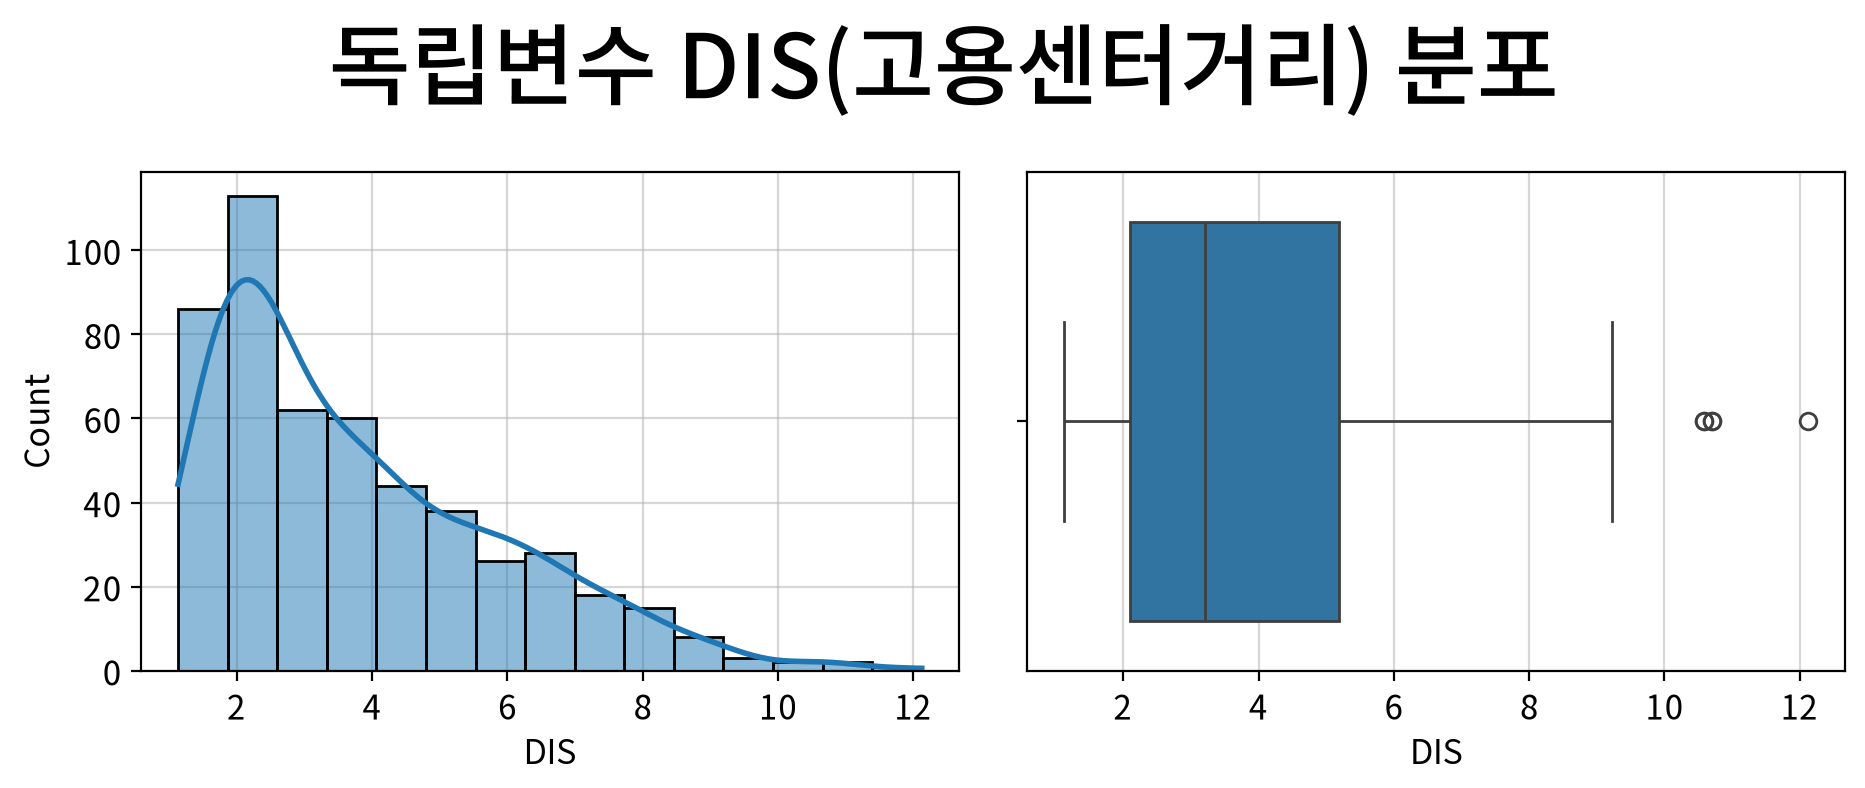

,DIS
count,506.000
mean,3.795
std,2.106
min,1.130
25%,2.100
50%,3.207
75%,5.188
max,12.127
rel_diff,0.183
rdiff_flag,diff


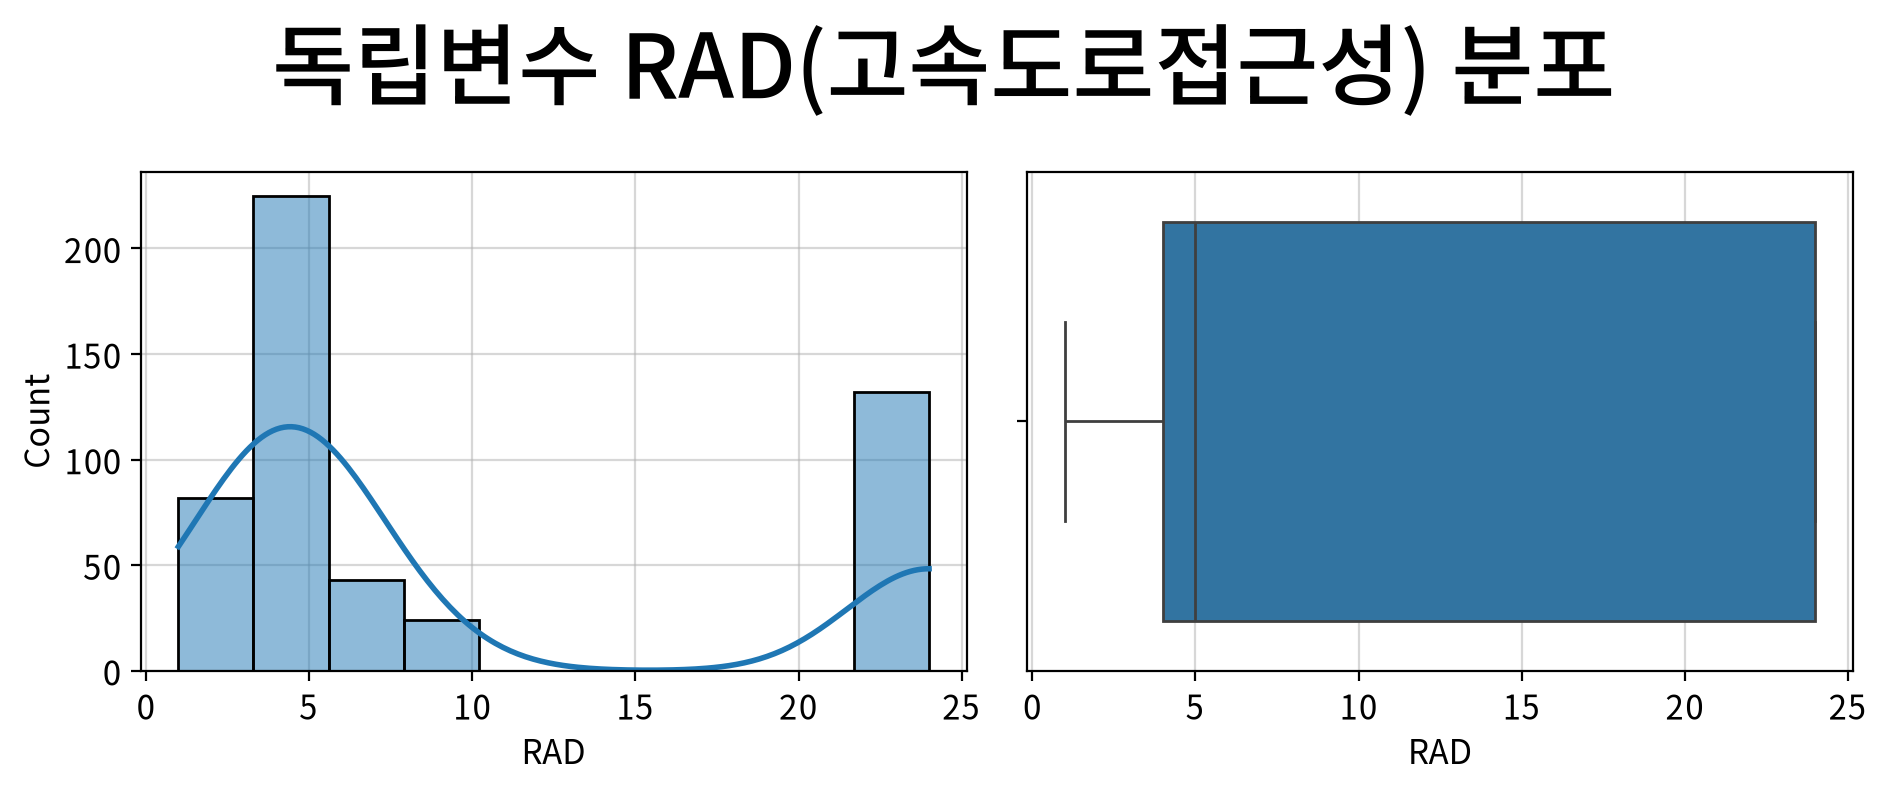

,RAD
count,506.000
mean,9.549
std,8.707
min,1.000
25%,4.000
50%,5.000
75%,24.000
max,24.000
rel_diff,0.910
rdiff_flag,large_diff


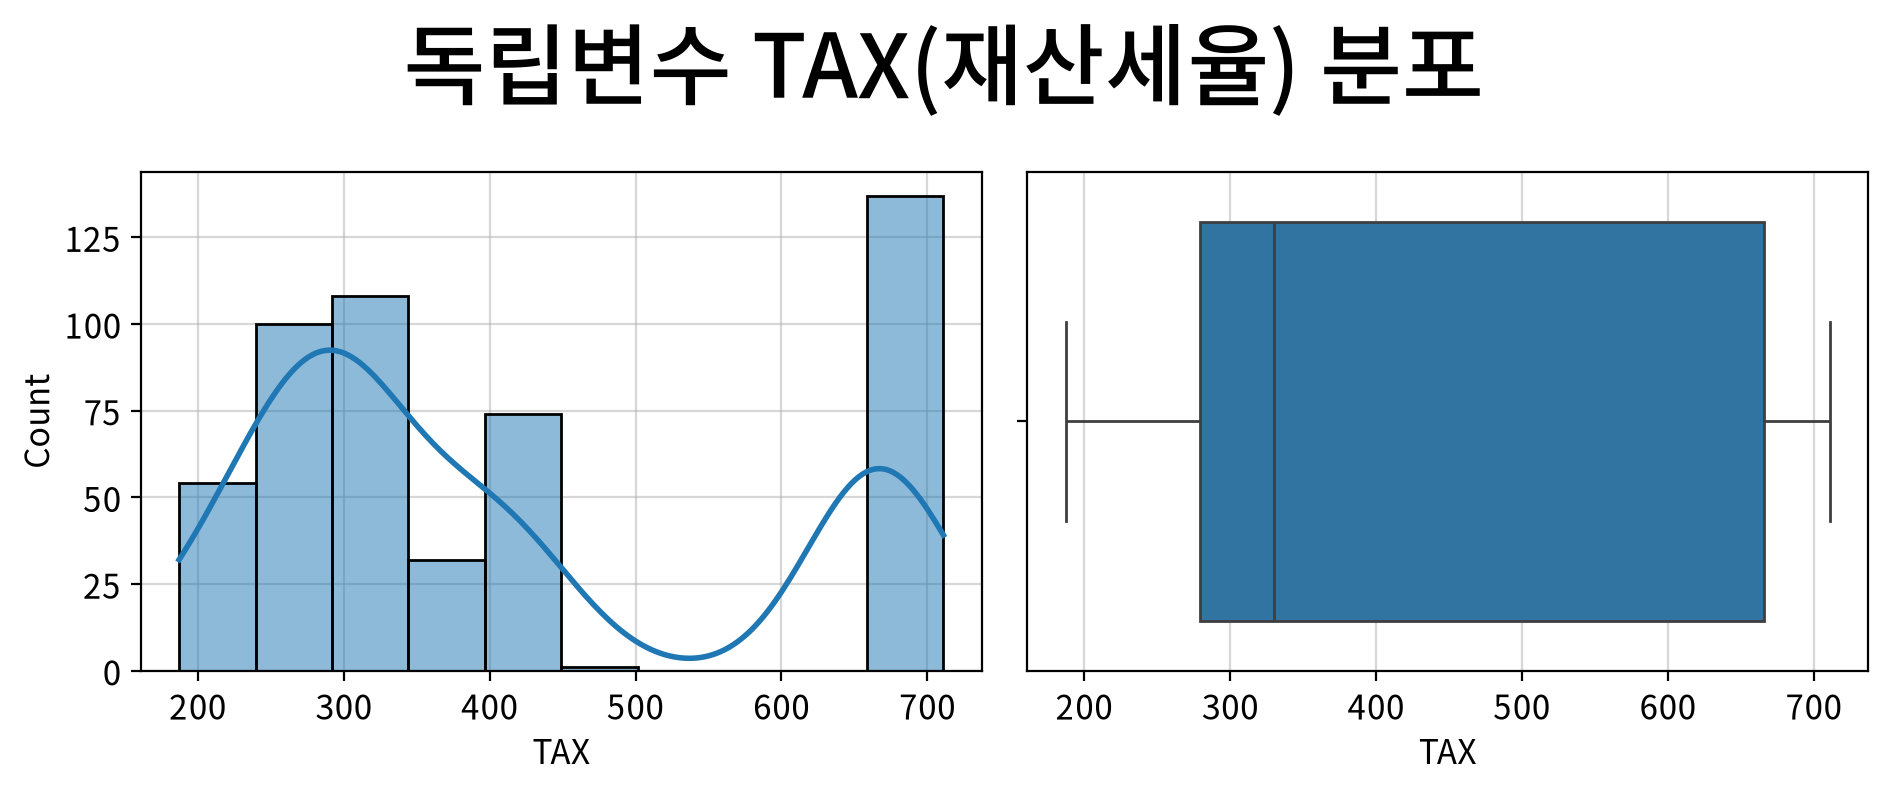

,TAX
count,506.000
mean,408.237
std,168.537
min,187.000
25%,279.000
50%,330.000
75%,666.000
max,711.000
rel_diff,0.237
rdiff_flag,diff


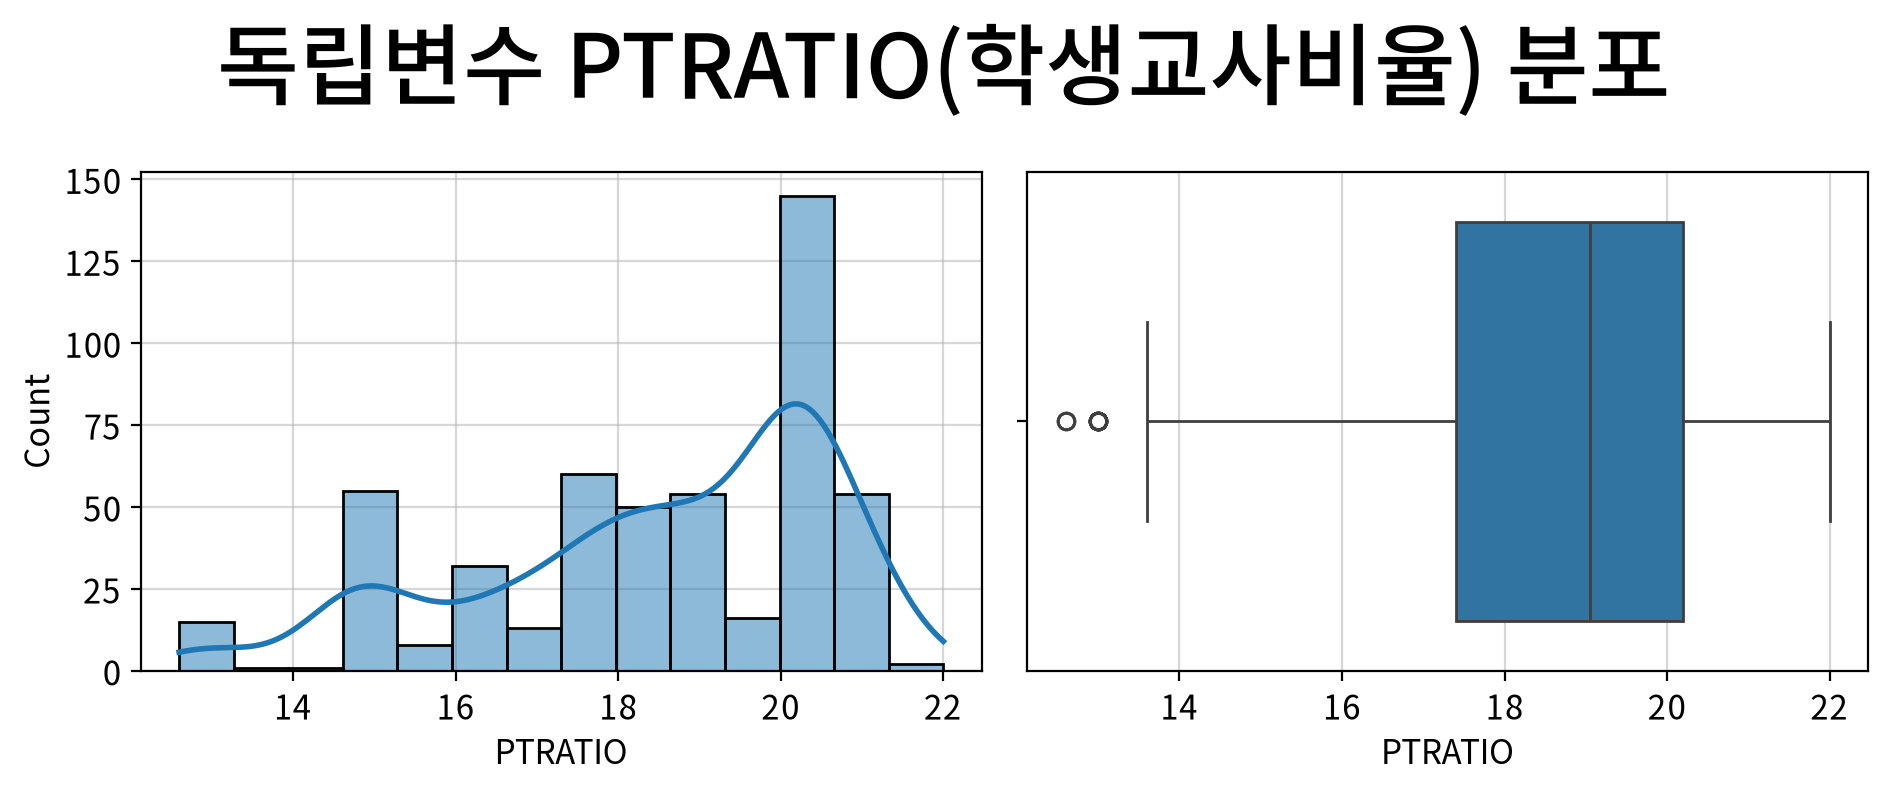

,PTRATIO
count,506.000
mean,18.456
std,2.165
min,12.600
25%,17.400
50%,19.050
75%,20.200
max,22.000
rel_diff,0.031
rdiff_flag,similar


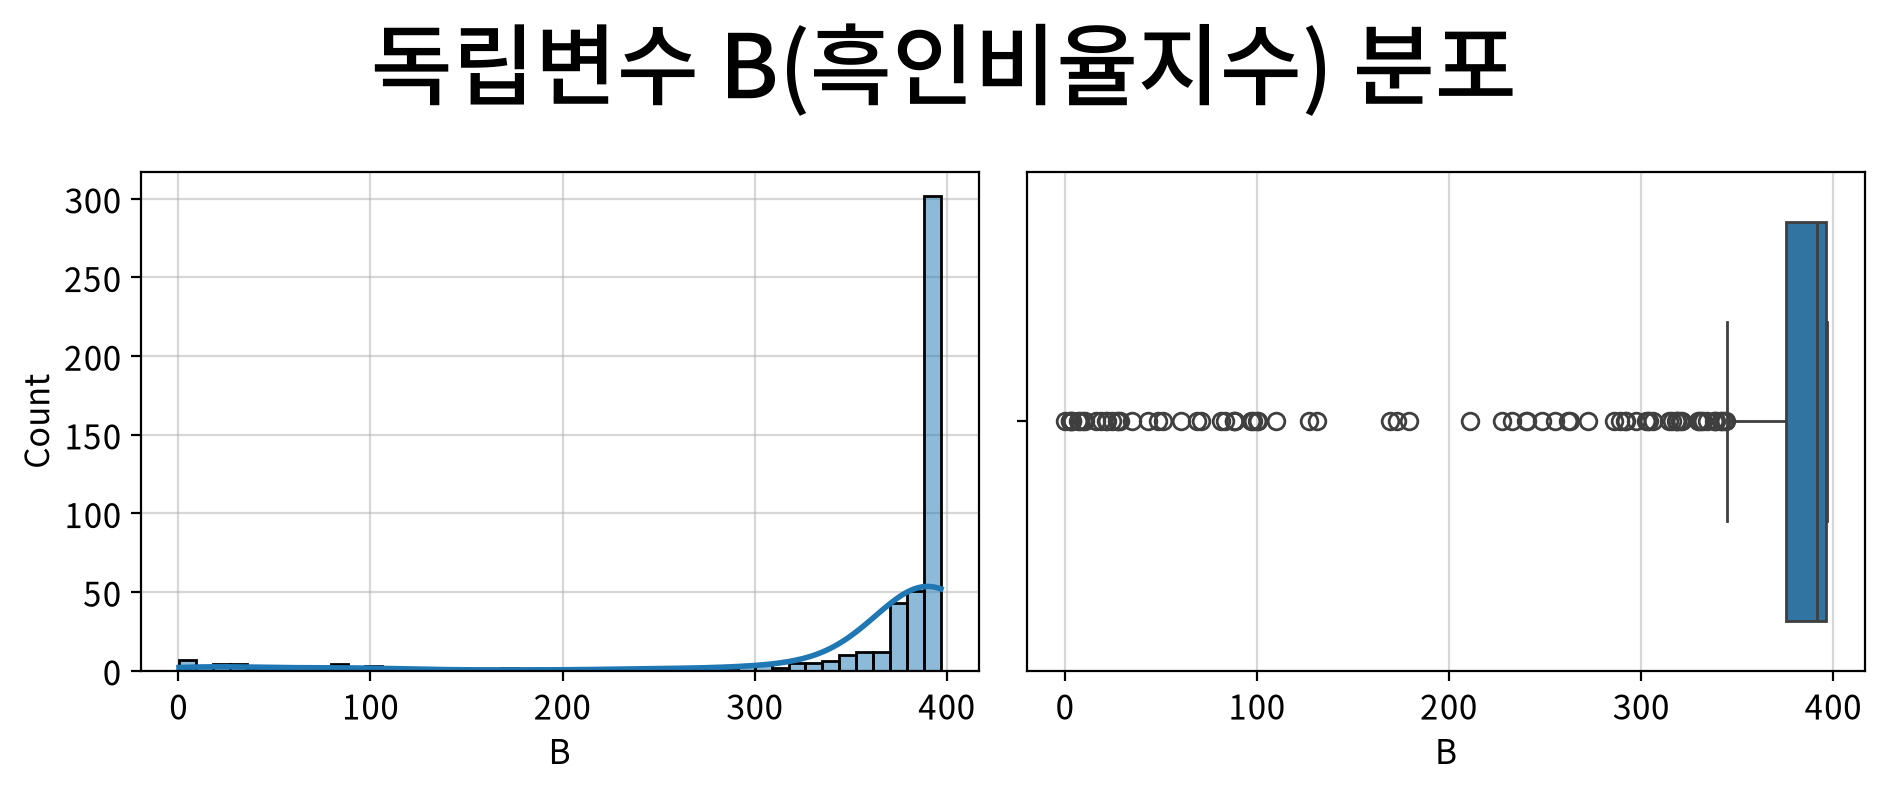

,B
count,506.000
mean,356.674
std,91.295
min,0.320
25%,375.377
50%,391.440
75%,396.225
max,396.900
rel_diff,0.089
rdiff_flag,similar


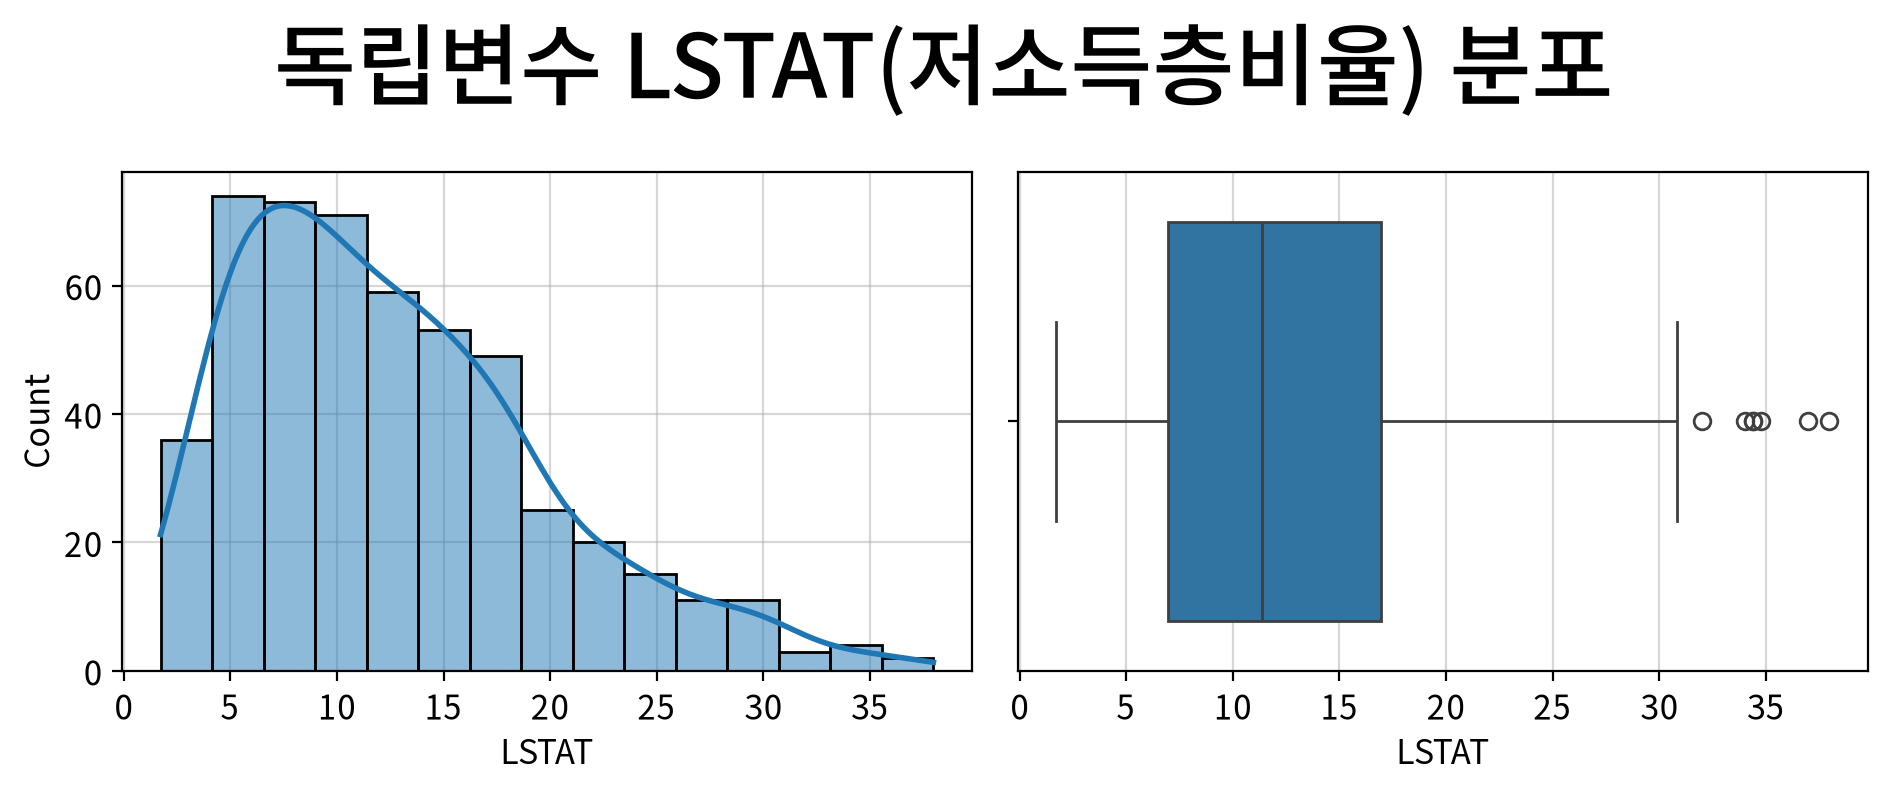

,LSTAT
count,506.000
mean,12.653
std,7.141
min,1.730
25%,6.950
50%,11.360
75%,16.955
max,37.970
rel_diff,0.114
rdiff_flag,diff


In [9]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2,width=960, height=400,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(desc[desc.index == f].T)

| 변수      | 분포 모양(왜도)   | 봉우리          | 이상치       | 이산점·군집       | 판단·조치              |
| ------- | ----------- | ------------ | --------- | ------------ | ------------------ |
| CRIM    | 매우 강한 우편향   | 단봉(0 근처 집중)  | 많음(약 13%) | 0 값에 집중      | 로그 변환 + 이상치 처리     |
| ZN      | 강한 우편향      | 0에 큰 덩어리     | 많음(약 13%) | 0 값에 집중      | 로그1p 변환 + 이상치 처리   |
| INDUS   | 대칭에 가까움     | 다봉(쌍봉 경향)    | 거의 없음     | 특정 구간 군집     | 변환 불필요, 다봉만 유의     |
| NOX     | 약한 우편향      | 다봉 경향        | 없음        | —            | 그대로 사용 가능          |
| RM      | 대칭(정규에 가까움) | 단봉           | 양쪽에 소수    | —            | 그대로 사용 가능          |
| AGE     | 좌편향         | 단봉(100 쪽 몰림) | 없음        | 100 부근 집중    | 그대로 사용 가능          |
| DIS     | 우편향         | 단봉           | 소수        | —            | 로그 변환 고려           |
| RAD     | 우편향         | 뚜렷한 이봉       | 없음        | 24에 큰 군집     | 사실상 범주형 → 선형 가정 주의 |
| TAX     | 우편향         | 이봉           | 없음        | 666\~711에 군집 | 사실상 범주형 → 선형 가정 주의 |
| PTRATIO | 좌편향         | 다봉(값 군집)     | 소수        | 특정 값에 집중     | 그대로 사용 가능          |
| B       | 매우 강한 좌편향   | 단봉(396 쪽 몰림) | 많음(약 15%) | 396 부근 집중    | 역로그 변환 + 이상치 처리    |
| LSTAT   | 우편향         | 단봉           | 소수        | —            | 로그 변환 고려           |

#### 2. 명목형 독립변수 분포 시각화

- 명목형은 분포 모양, 왜도 대신 범주의 균형/불균형을 점검하여\
"그대로 검정/모델에 넣어도 되는가?"를 판단한다.

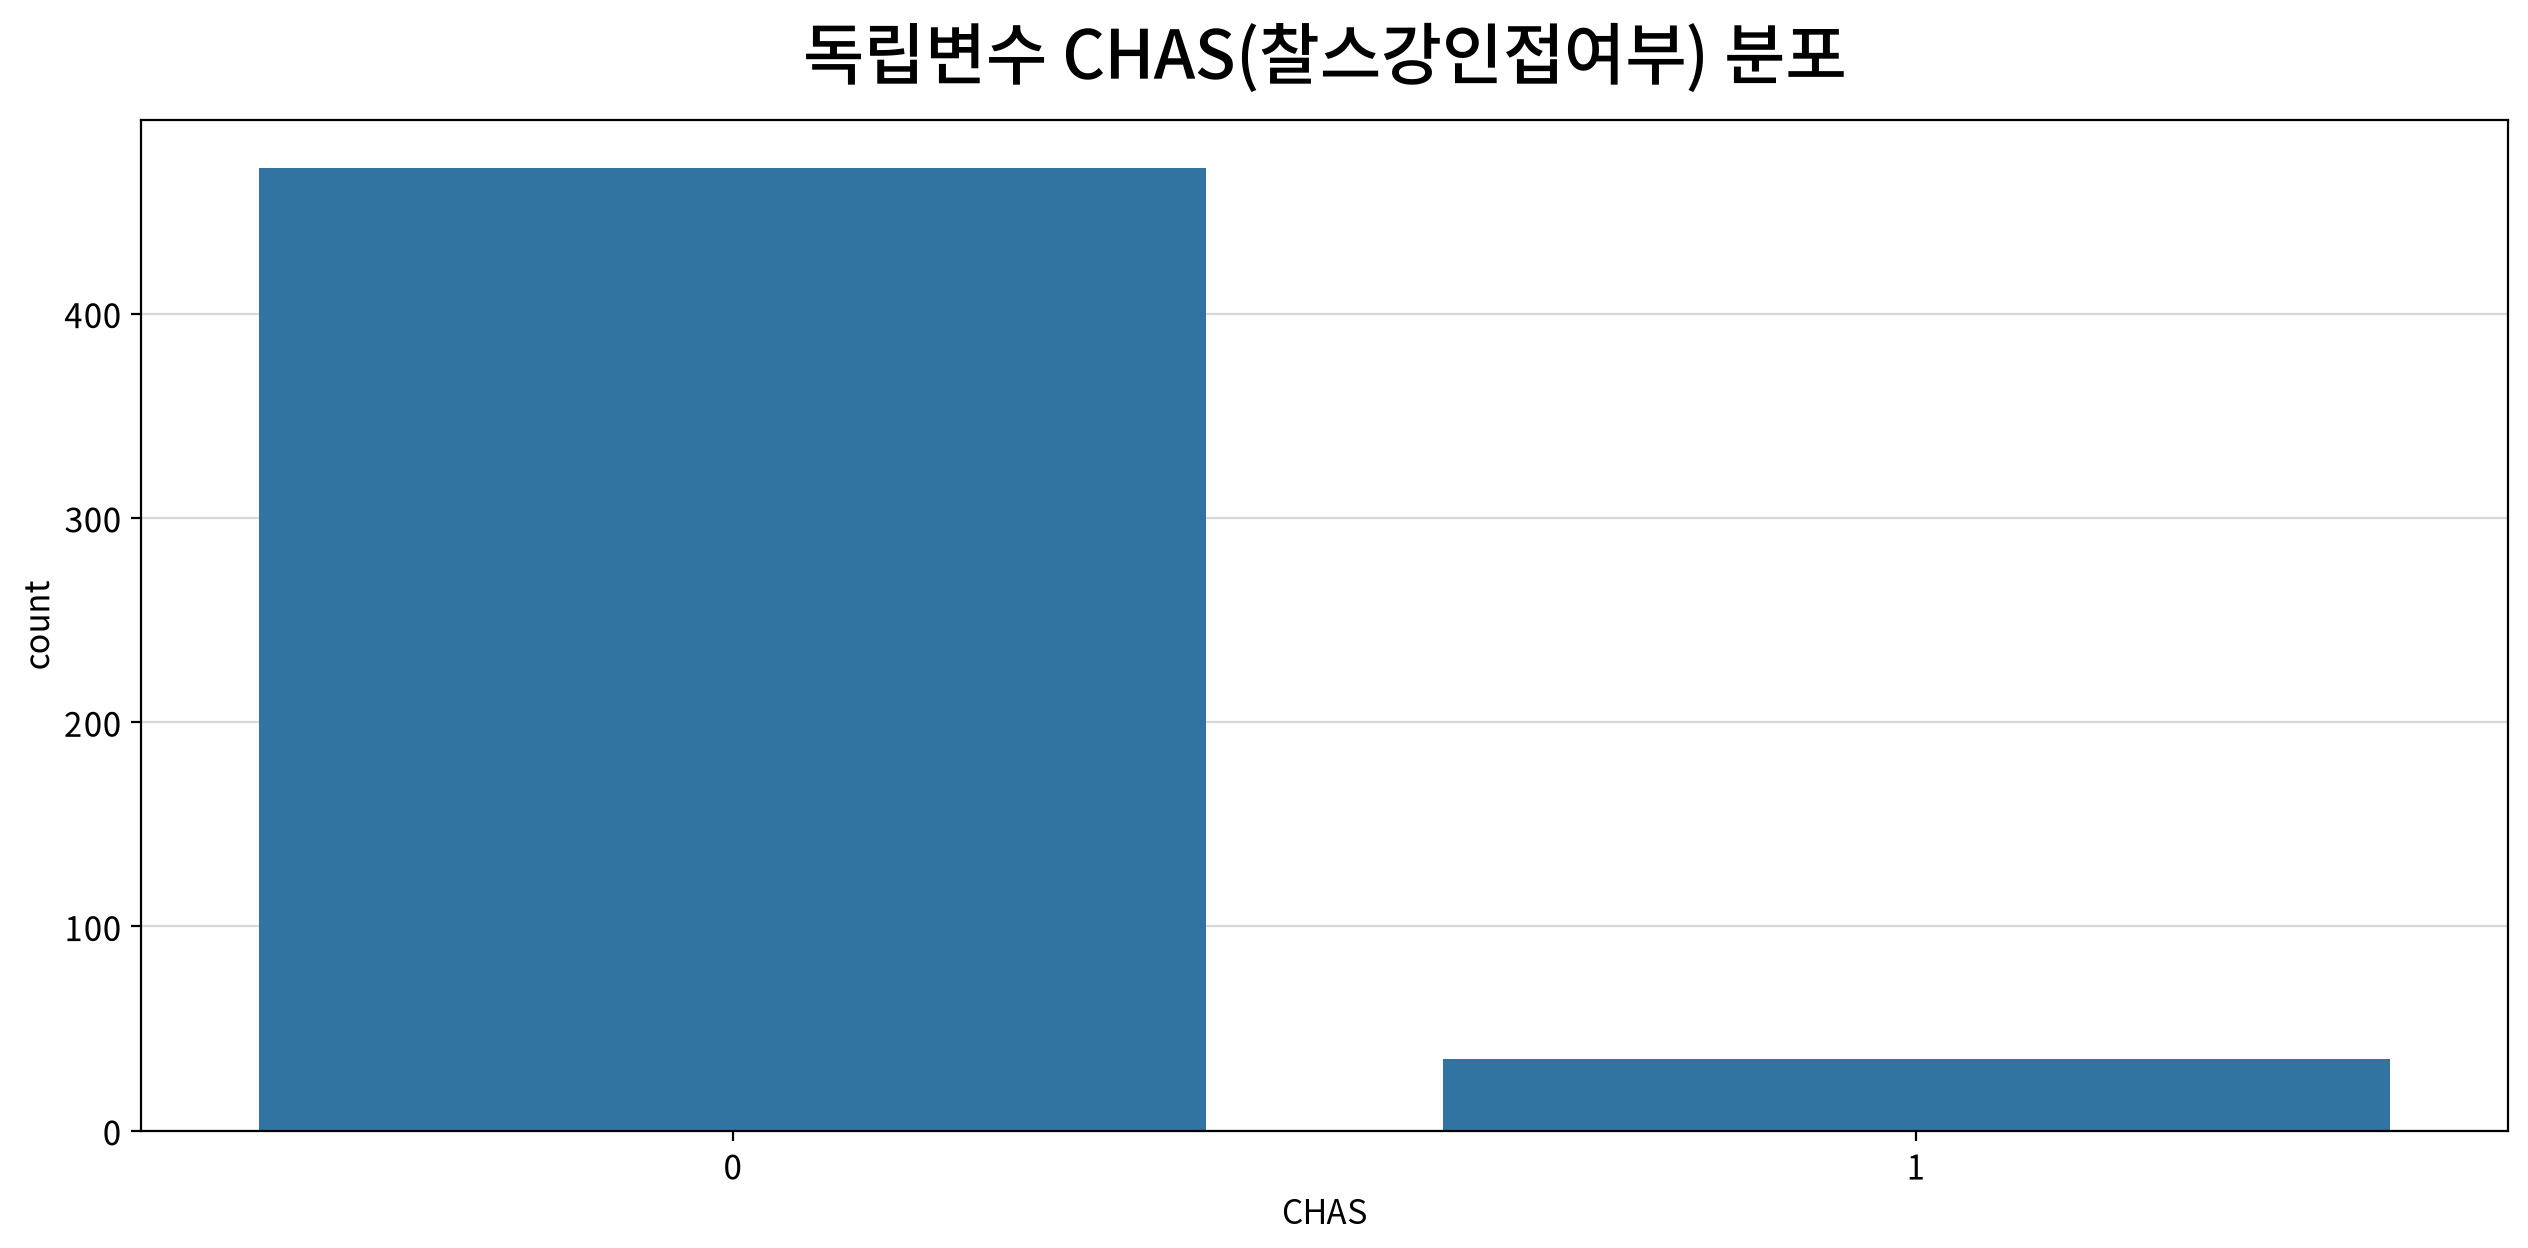

,count,unique,top,freq
CHAS,506,2,0,471


,빈도,비율
CHAS,,
0,471,0.931
1,35,0.069


In [10]:
for n in nominal_cols:
    # 명목형 분포는 카운트 플롯으로 처리한다.
    my_plot.countplot(data=df, x=n, title=f"독립변수 {n}({column_means[n]}) 분포")

    # 명목형 기술통계량
    display(cat_desc[[n]].T)

    # 추가적으로 빈도표 생성
    freq = df[n].value_counts().rename("빈도").to_frame()
    # value_counts(normalize=True)
    # --> 전체 고유값의 개수(빈도수) 대신 전체 데이터의 비율을 계산
    freq["비율"] = df[n].value_counts(normalize=True)
    display(freq)

| 변수   | 범주 수                 | 빈도(비율)                        | 균형 여부  | 판단·조치                      |
| ---- | -------------------- | ----------------------------- | ------ | -------------------------- |
| CHAS | 2 (0=강변 아님, 1=강변 인접) | 0: 471 (93.1%) / 1: 35 (6.9%) | 심한 불균형 | T검정 대상, 소수 집단(35건)이라 해석 신중 |

> CHAS는 2집단 명목형 -> 종속변수(MEDV)와의 차이는 T검정으로 확인   
> 강변 인접(1)이 35건(6.9%)뿐 -> 표본 불균형으로 검정력 낮음 -> 결과를 단정하지 말고 신중히 해석   
> 강변 프리미엄의 유의성은 확인할 가치가 있으므로 버리지 않고 유지

---

## 연습문제

### 의료보험 청구 비용 데이터셋의 다변량 시각화

보험사 데이터 분석가가 되어,\
청구 비용을 예측하는 선형회귀 모델에 넣을 독립변수를 골라야 합니다.   
- 본격적으로 EDA를 시작해야 합니다. 단변량 데이터를 시각화하고 EDA 관점의 인사이트를 발굴하세요.

> **insurance_qtcheck** : 보험 비용 데이터셋의 품질 검사 완료 버전\
> **insurance_qtcheck_desc** : 보험 비용 데이터셋의 연속형 변수에 대한 기술 통계량\
> **insurance_qtcheck_category_desc** : 보험 비용 데이터셋의 범주형 변수에 대한 기술 통계량

1. 종속변수의 분포를 시각화하고 기술 통계량과 비교하여 인사이트를 발굴하세요.
2. 연속형 독립변수의 분포를 시각화하고 기술 통계량과 비교하여 인사이트를 발굴하세요.
3. 명목형 독립변수의 분포를 시각화하고 기술 통계량과 비교하여 인사이트를 발굴하세요.

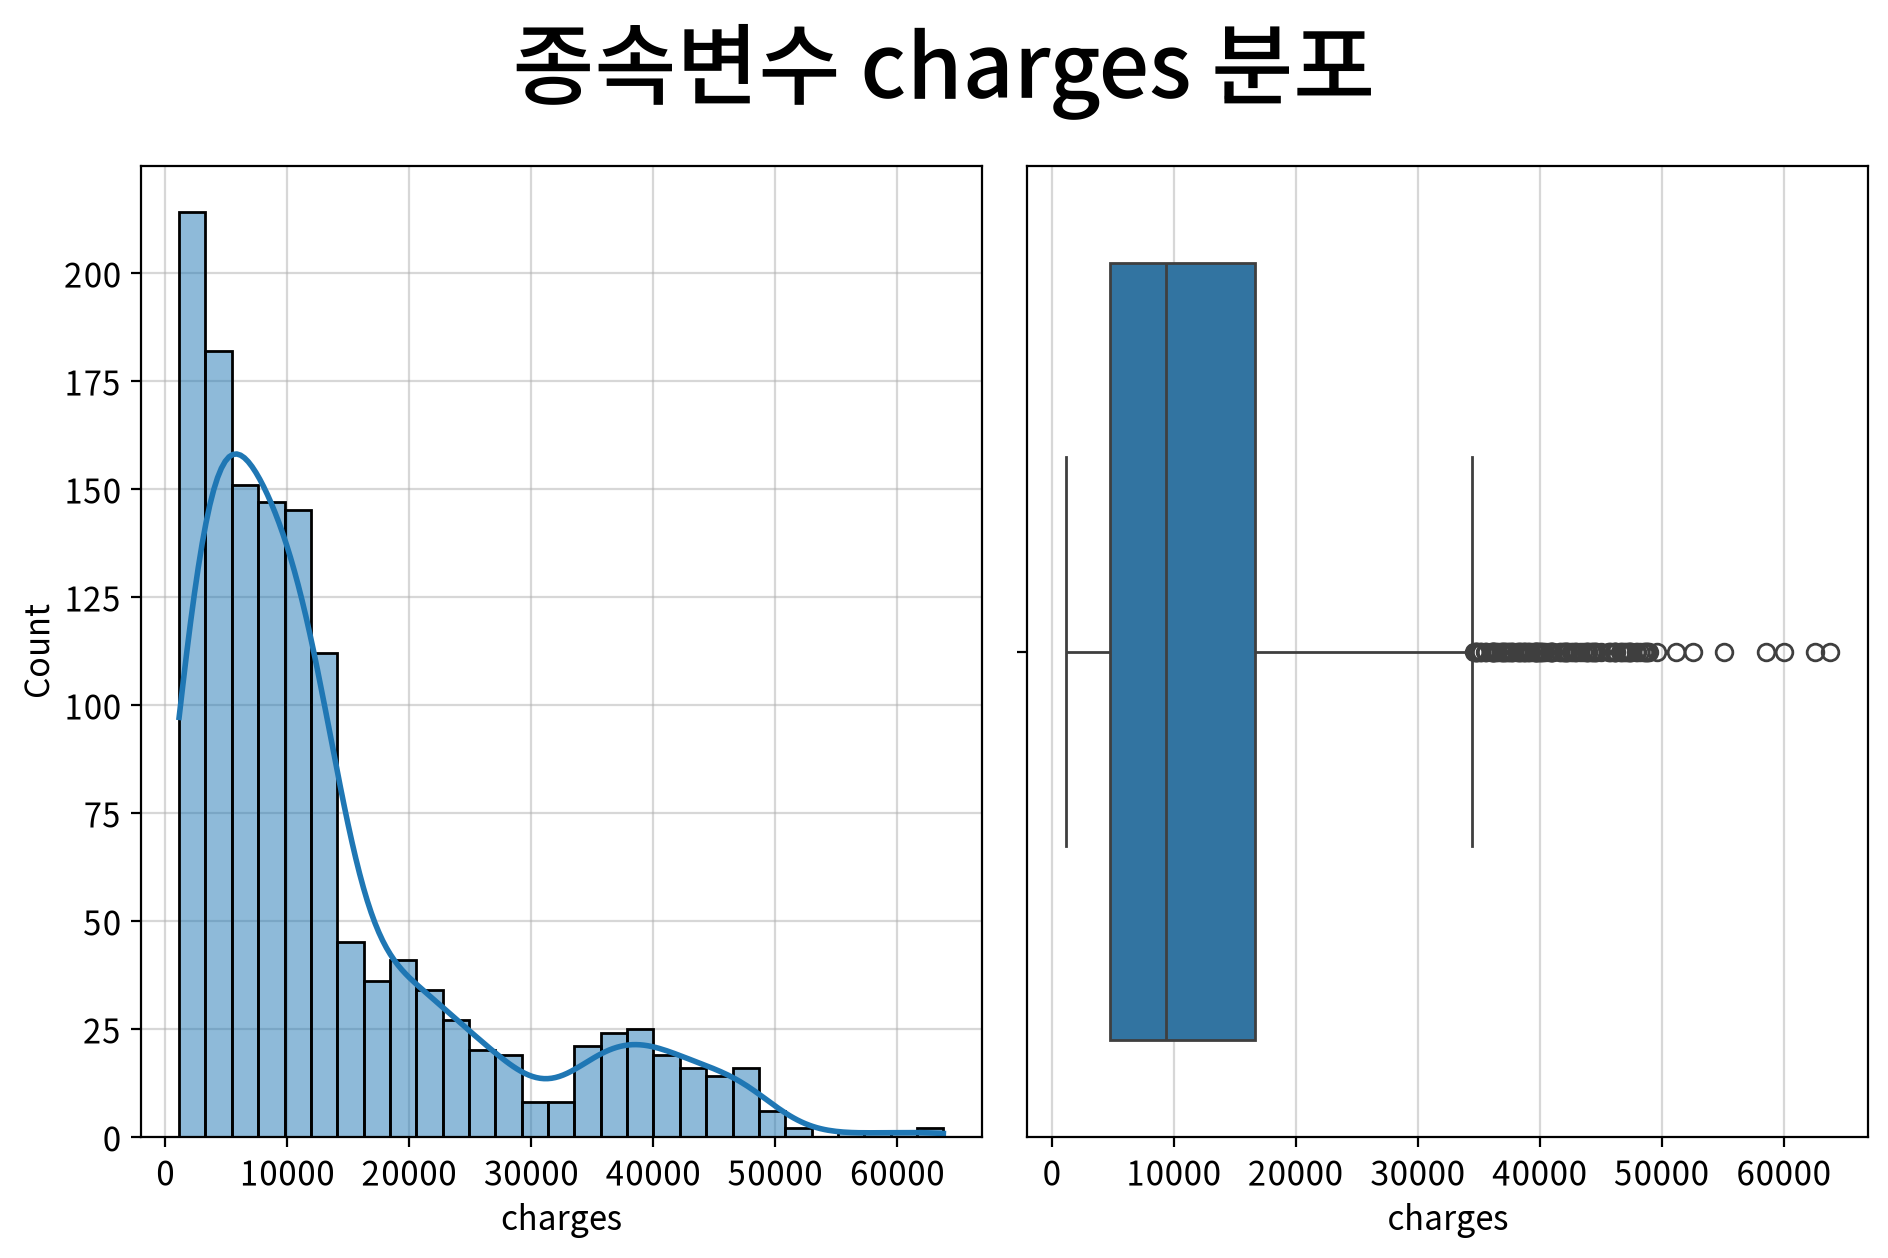

,charges
count,1337.000
mean,13279.121
std,12110.360
min,1121.874
25%,4746.344
50%,9386.161
75%,16657.717
max,63770.428
rel_diff,0.415
rdiff_flag,diff


In [11]:
# 연속형 변수에 대한 분석 수행
fig, ax = my_plot.init(rows=1, cols=2,
                       title=f"종속변수 {target1} 분포", width=960, height=640)
my_plot.histplot(data=df2, x=target1, kde=True, ax=ax[0])
my_plot.boxplot(data=df2, x=target1, ax=ax[1])
my_plot.show()

# 연속형 변수 기술통계량에서 종속변수에 대한 부분만 추출
desc1[desc1.index == target1].T

> 종속변수는 예측 대상이므로 **분포 모양과 변환 필요성**을 가장 먼저 확정한다.
> 모양은 그래프로 보고, 정확한 수치는 함께 출력된 **기술통계량(`desc`) 표**로 확인한다.

| 점검 항목 | `charges`(보험청구비용) 관찰 내용 |
|---|---|
| 분포 모양(왜도) | **강한 우편향** — skew 1.515(`right tail`), 평균 13,279 > 중앙값 9,386 |
| 봉우리 수 | 5,000 부근 주봉 + **35,000~45,000에 2차 봉우리**(KDE) → 고비용 하위집단 암시 |
| 이상치 | 상단에만 139건(**10.4%**), 하단 0건 — 상한 34,525 초과 |
| 첨도 | kurt 1.604(`leptokurtic`) — 중앙 집중 + 두꺼운 오른쪽 꼬리 |
| 값의 범위 | 1,122 ~ 63,770 (최댓값이 중앙값의 약 6.8배) |

**판단·조치**
- 우편향이 뚜렷하므로 회귀 모델 투입 시 **`log1p(charges)` 변환**으로 왜도를 완화한다(`desc`의 `log_need = log1p`와 일치).
- 상단 이상치 10.4%는 **오류가 아니라 실제 고액 청구 집단**으로 보이므로 단순 제거 대상이 아니다.
- 2차 봉우리는 특정 설명변수(예: `smoker`)로 집단이 갈라진다는 신호일 수 있으므로 **이변량 분석에서 확인**한다.

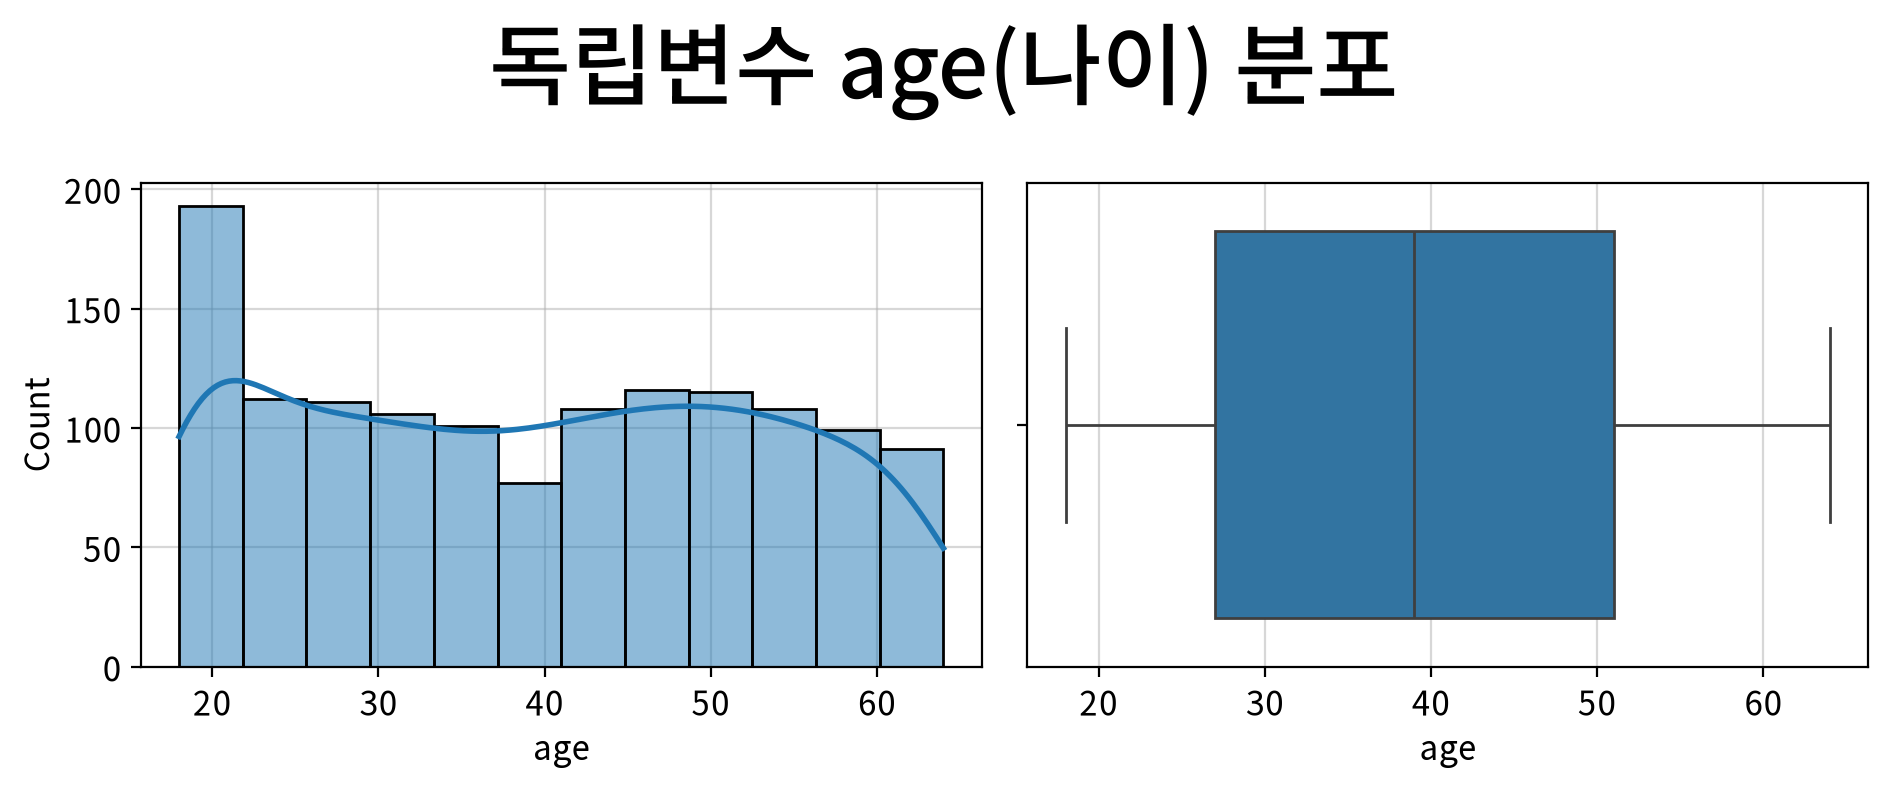

,age
count,1337.000
mean,39.222
std,14.044
min,18.000
25%,27.000
50%,39.000
75%,51.000
max,64.000
rel_diff,0.006
rdiff_flag,similar


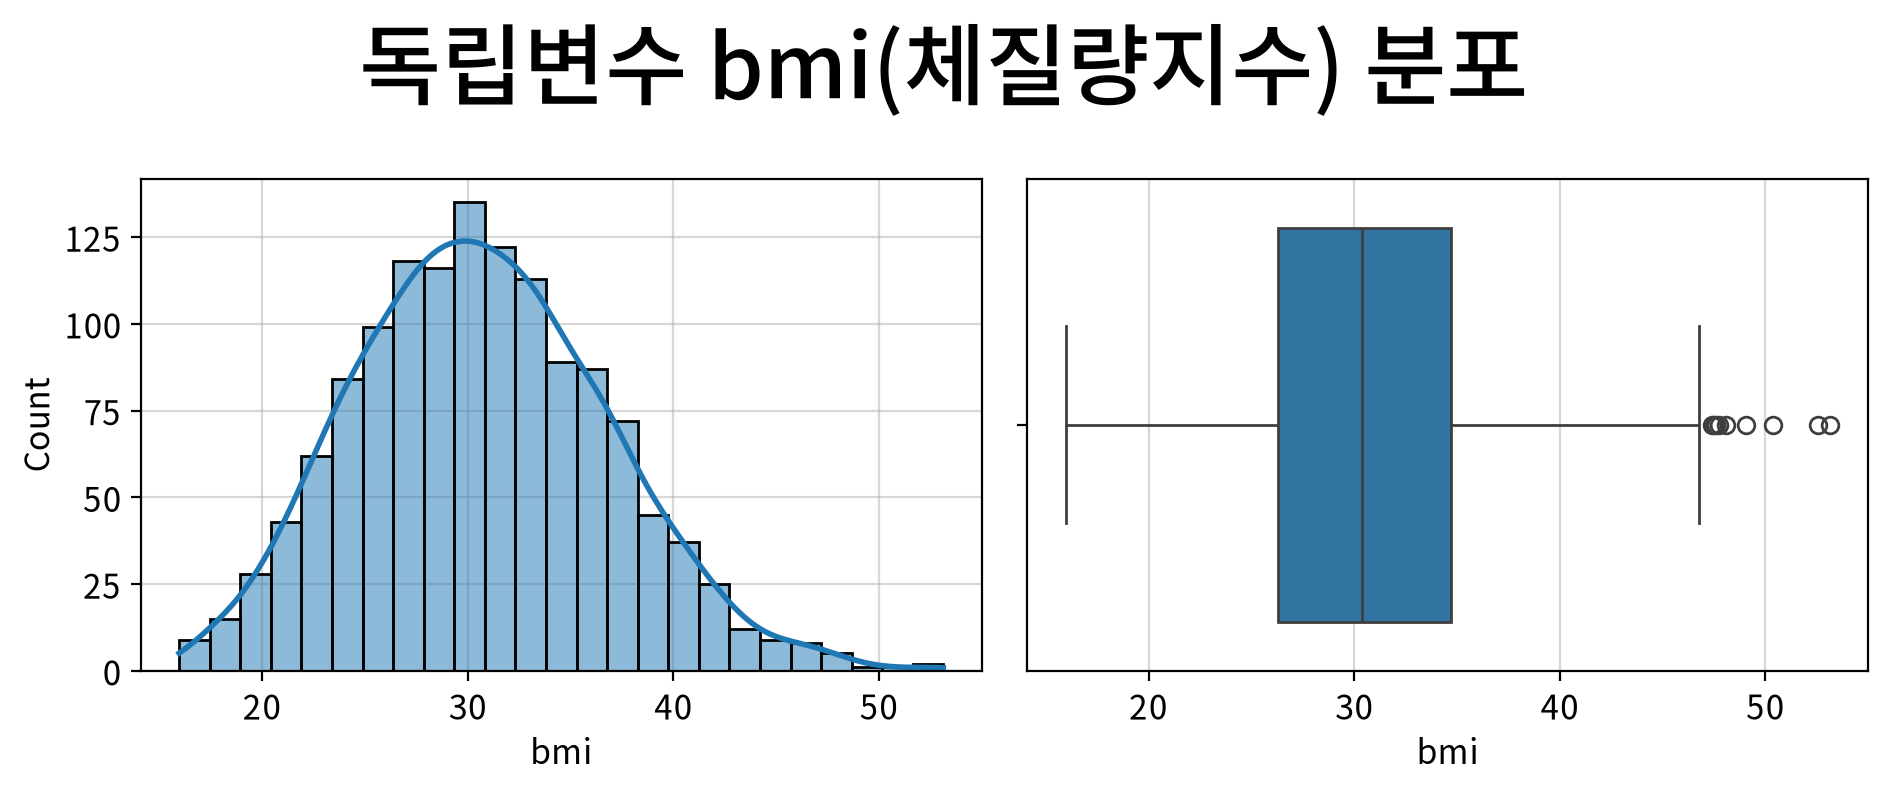

,bmi
count,1337.000
mean,30.663
std,6.100
min,15.960
25%,26.290
50%,30.400
75%,34.700
max,53.130
rel_diff,0.009
rdiff_flag,similar


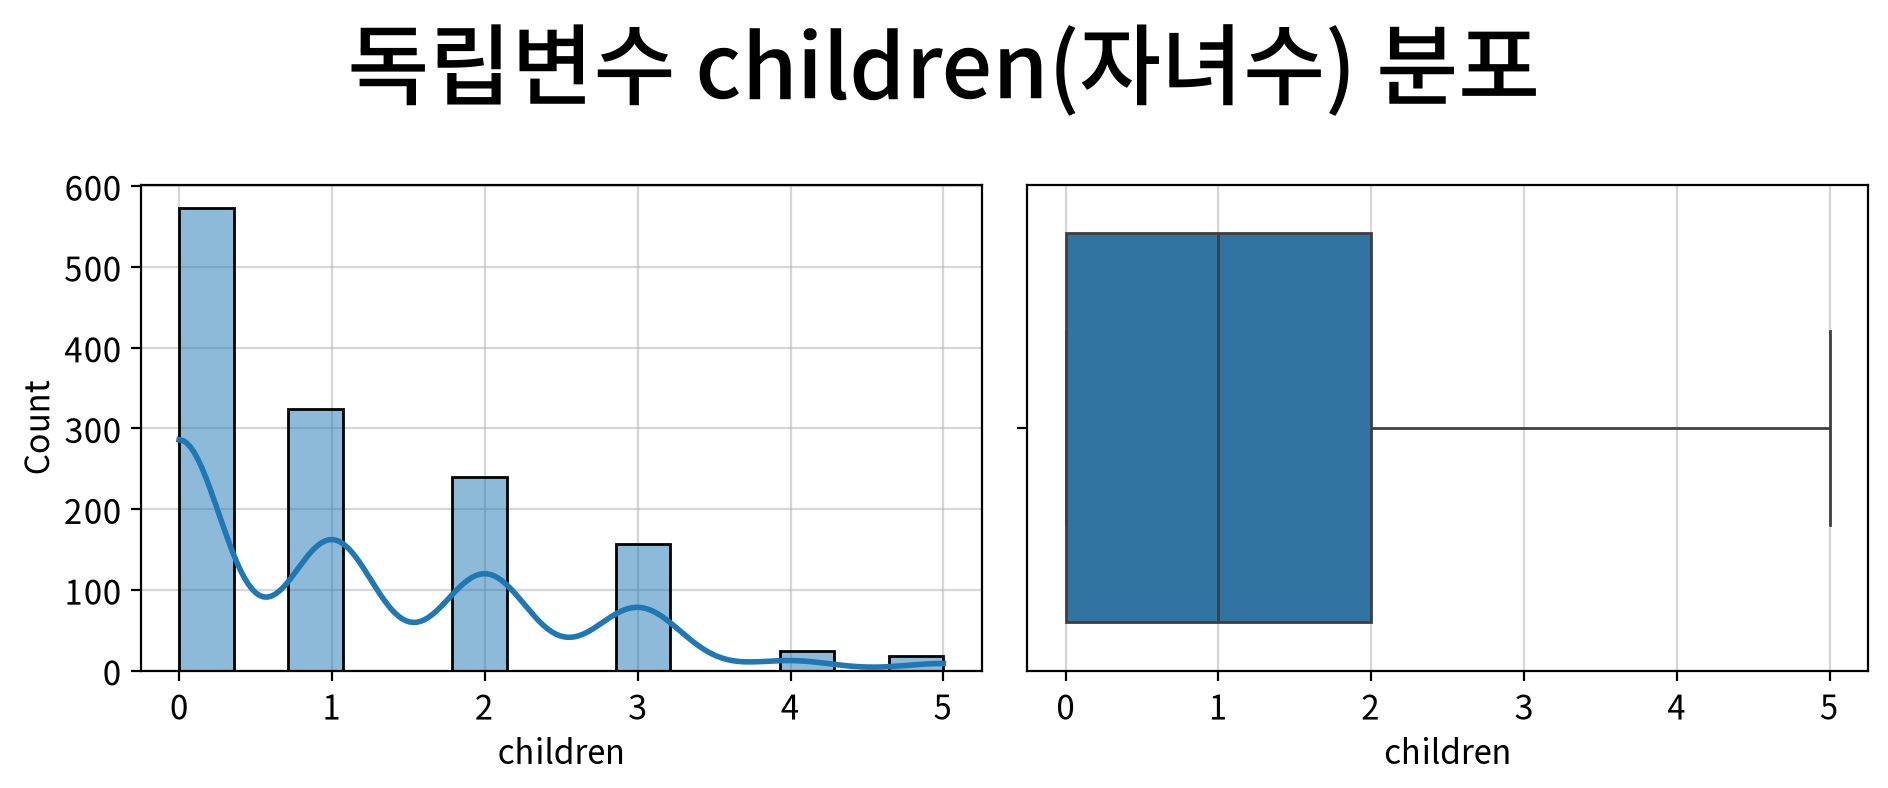

,children
count,1337.000
mean,1.096
std,1.206
min,0.000
25%,0.000
50%,1.000
75%,2.000
max,5.000
rel_diff,0.096
rdiff_flag,similar


In [12]:
# 연속형 독립변수의 단변량 분석
for f in continuous_cols1:
    fig, ax = my_plot.init(rows=1, cols=2,width=960, height=400,
                           title=f"독립변수 {f}({column_means1[f]}) 분포")
    my_plot.histplot(data=df2, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df2, x=f, ax=ax[1])
    my_plot.show()

    display(desc1[desc1.index == f].T)

| 통계 항목                | age         | bmi         | children    |
| -------------------- | ----------- | ----------- | ----------- |
| count                | 1337.000    | 1337.000    | 1337.000    |
| mean                 | 39.222      | 30.663      | 1.096       |
| std                  | 14.044      | 6.100       | 1.206       |
| min                  | 18.000      | 15.960      | 0.000       |
| 25%                  | 27.000      | 26.290      | 0.000       |
| 50%                  | 39.000      | 30.400      | 1.000       |
| 75%                  | 51.000      | 34.700      | 2.000       |
| max                  | 64.000      | 53.130      | 5.000       |
| rel_diff             | 0.006       | 0.009       | 0.096       |
| rdiff_flag           | similar     | similar     | similar     |
| iqr                  | 24.000      | 8.410       | 2.000       |
| upper_bound          | 87.000      | 47.315      | 5.000       |
| lower_bound          | -9.000      | 13.675      | -3.000      |
| upper_outliers       | 0           | 9           | 0           |
| upper_outliers_ratio | 0.000       | 0.007       | 0.000       |
| lower_outliers       | 0           | 0           | 0           |
| lower_outliers_ratio | 0.000       | 0.000       | 0.000       |
| outliers             | 0           | 9           | 0           |
| outliers_ratio       | 0.000       | 0.007       | 0.000       |
| skew                 | 0.055       | 0.284       | 0.937       |
| skew_interpret       | symmetric   | symmetric   | right tail  |
| kurt                 | -1.244      | -0.053      | 0.201       |
| kurt_interpret       | platykurtic | platykurtic | leptokurtic |
| log_need             | none        | none        | log1p       |

> 연속형 독립변수는 **분포 모양 · 봉우리 · 이상치 · 이산성**을 점검해
> "그대로 검정·모델에 넣어도 되는가?"를 판단한다. (수치는 `desc` 표 기준)

| 변수 | 분포 모양(왜도) | 봉우리 | 이상치 | 이산점·군집 | 판단·조치 |
|---|---|---|---|---|---|
| `age`(가입자 나이) | 대칭·**평탄**(skew 0.06, kurt −1.24) | 뚜렷한 단봉 없음 | 없음(0건) | **18~19세에 스파이크**(각 69·67명, 20세 이상 평균 약 27명의 2.5배) | 그대로 사용 가능 |
| `bmi`(체질량 지수) | **거의 대칭**·종 모양(skew 0.28, kurt −0.05) | 단봉(30 부근) | 상단 9건(**0.7%**) | — | 그대로 사용 가능(정규 가정 양호) |
| `children`(부양 자녀 수) | 우편향(skew 0.94) | 0에 최빈(573건) | 없음(0건) | **이산값 0~5뿐**, 4·5는 각 25/18건 | 연속 취급 주의 |

**판단·조치**
- 세 변수 모두 **심한 치우침·과다 이상치 없음 → 로그 변환 불필요**.
- `children`은 `desc`가 `log_need = log1p`로 표시하지만, 이는 skew만 보고 **기계적으로 판정**한 결과다. 값이 6종(0~5)뿐인 **이산 count 변수**라 로그 변환의 실익이 없다. (KDE가 값마다 물결치는 것도 이산 변수에 밀도 곡선을 씌운 착시이므로 봉우리로 읽지 않는다.)
- `age`의 18~19세 스파이크는 청년 가입자가 몰린 **표본 특성**이므로 오류로 보지 않되, 나이 효과 해석 시 감안한다. (히스토그램 첫 막대가 유독 높은 것은 이 스파이크 때문이며, 막대 하나가 약 4개 나이를 묶은 구간임에 주의한다.)
- `age`·`bmi`는 정규 가정이 양호해 **모수 검정(상관·회귀)에 바로 투입 가능**하다.

> `children` 변수 처럼 단순히 기술통계량의 값만 가지고 기계적으로 판별할 경우 값의 범위가 넓지 않은 변수는 큰 변화가 없을 수 있으므로 처리에 주의를 요합니다.

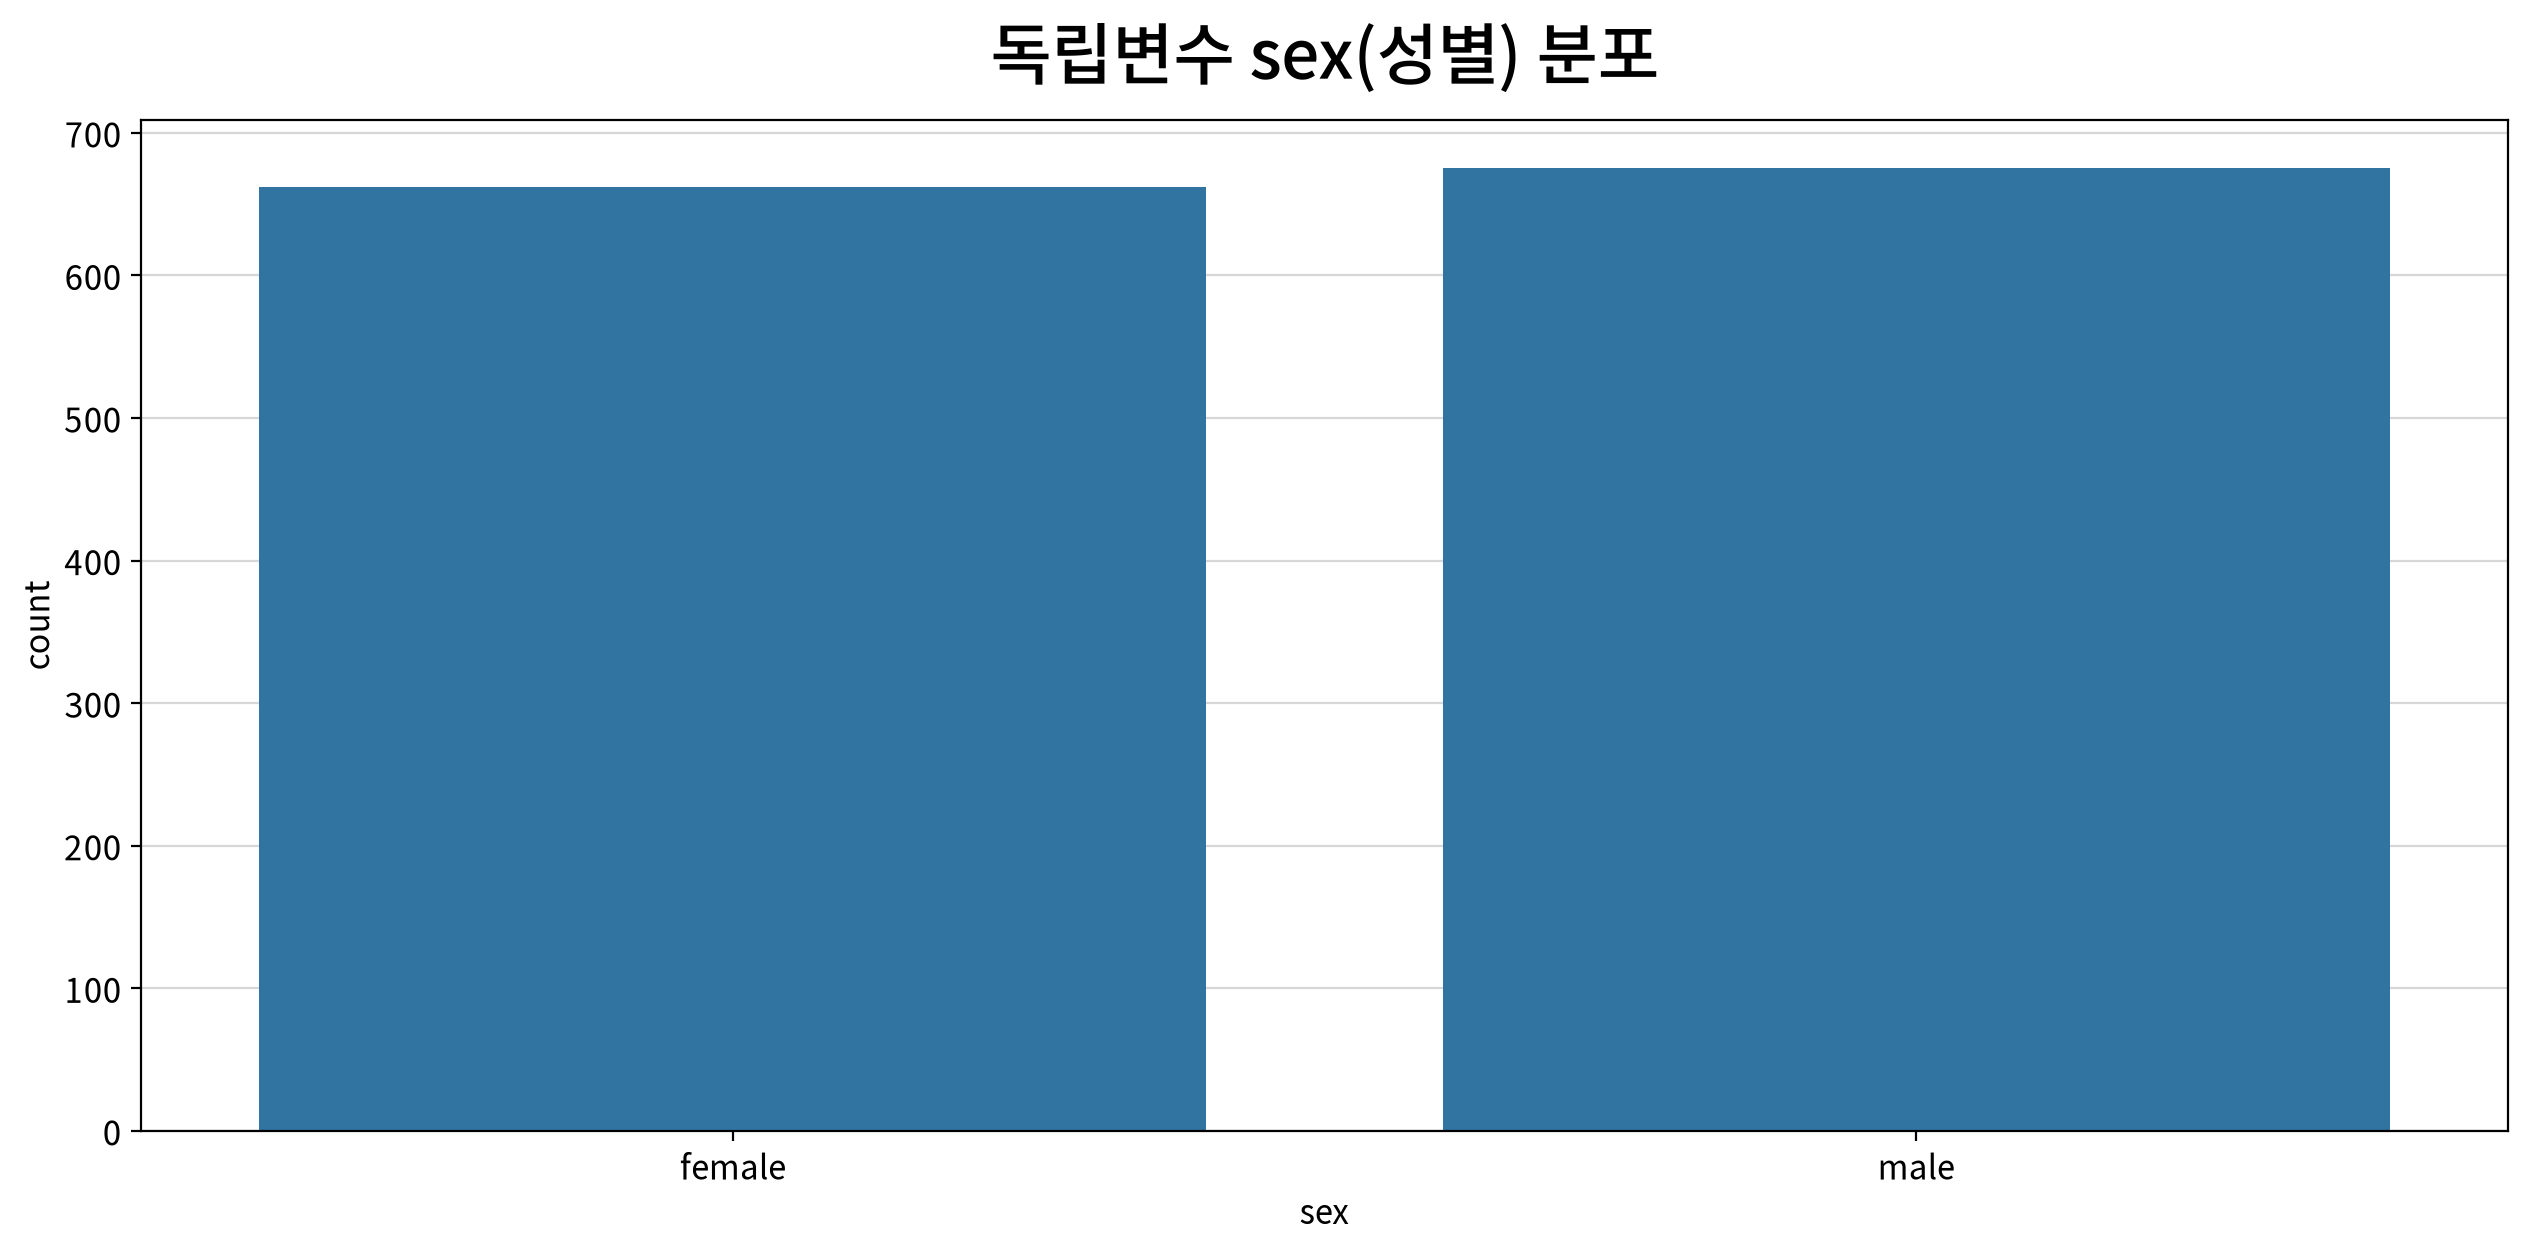

,count,unique,top,freq
sex,1337,2,male,675


,빈도,비율
sex,,
male,675,0.505
female,662,0.495


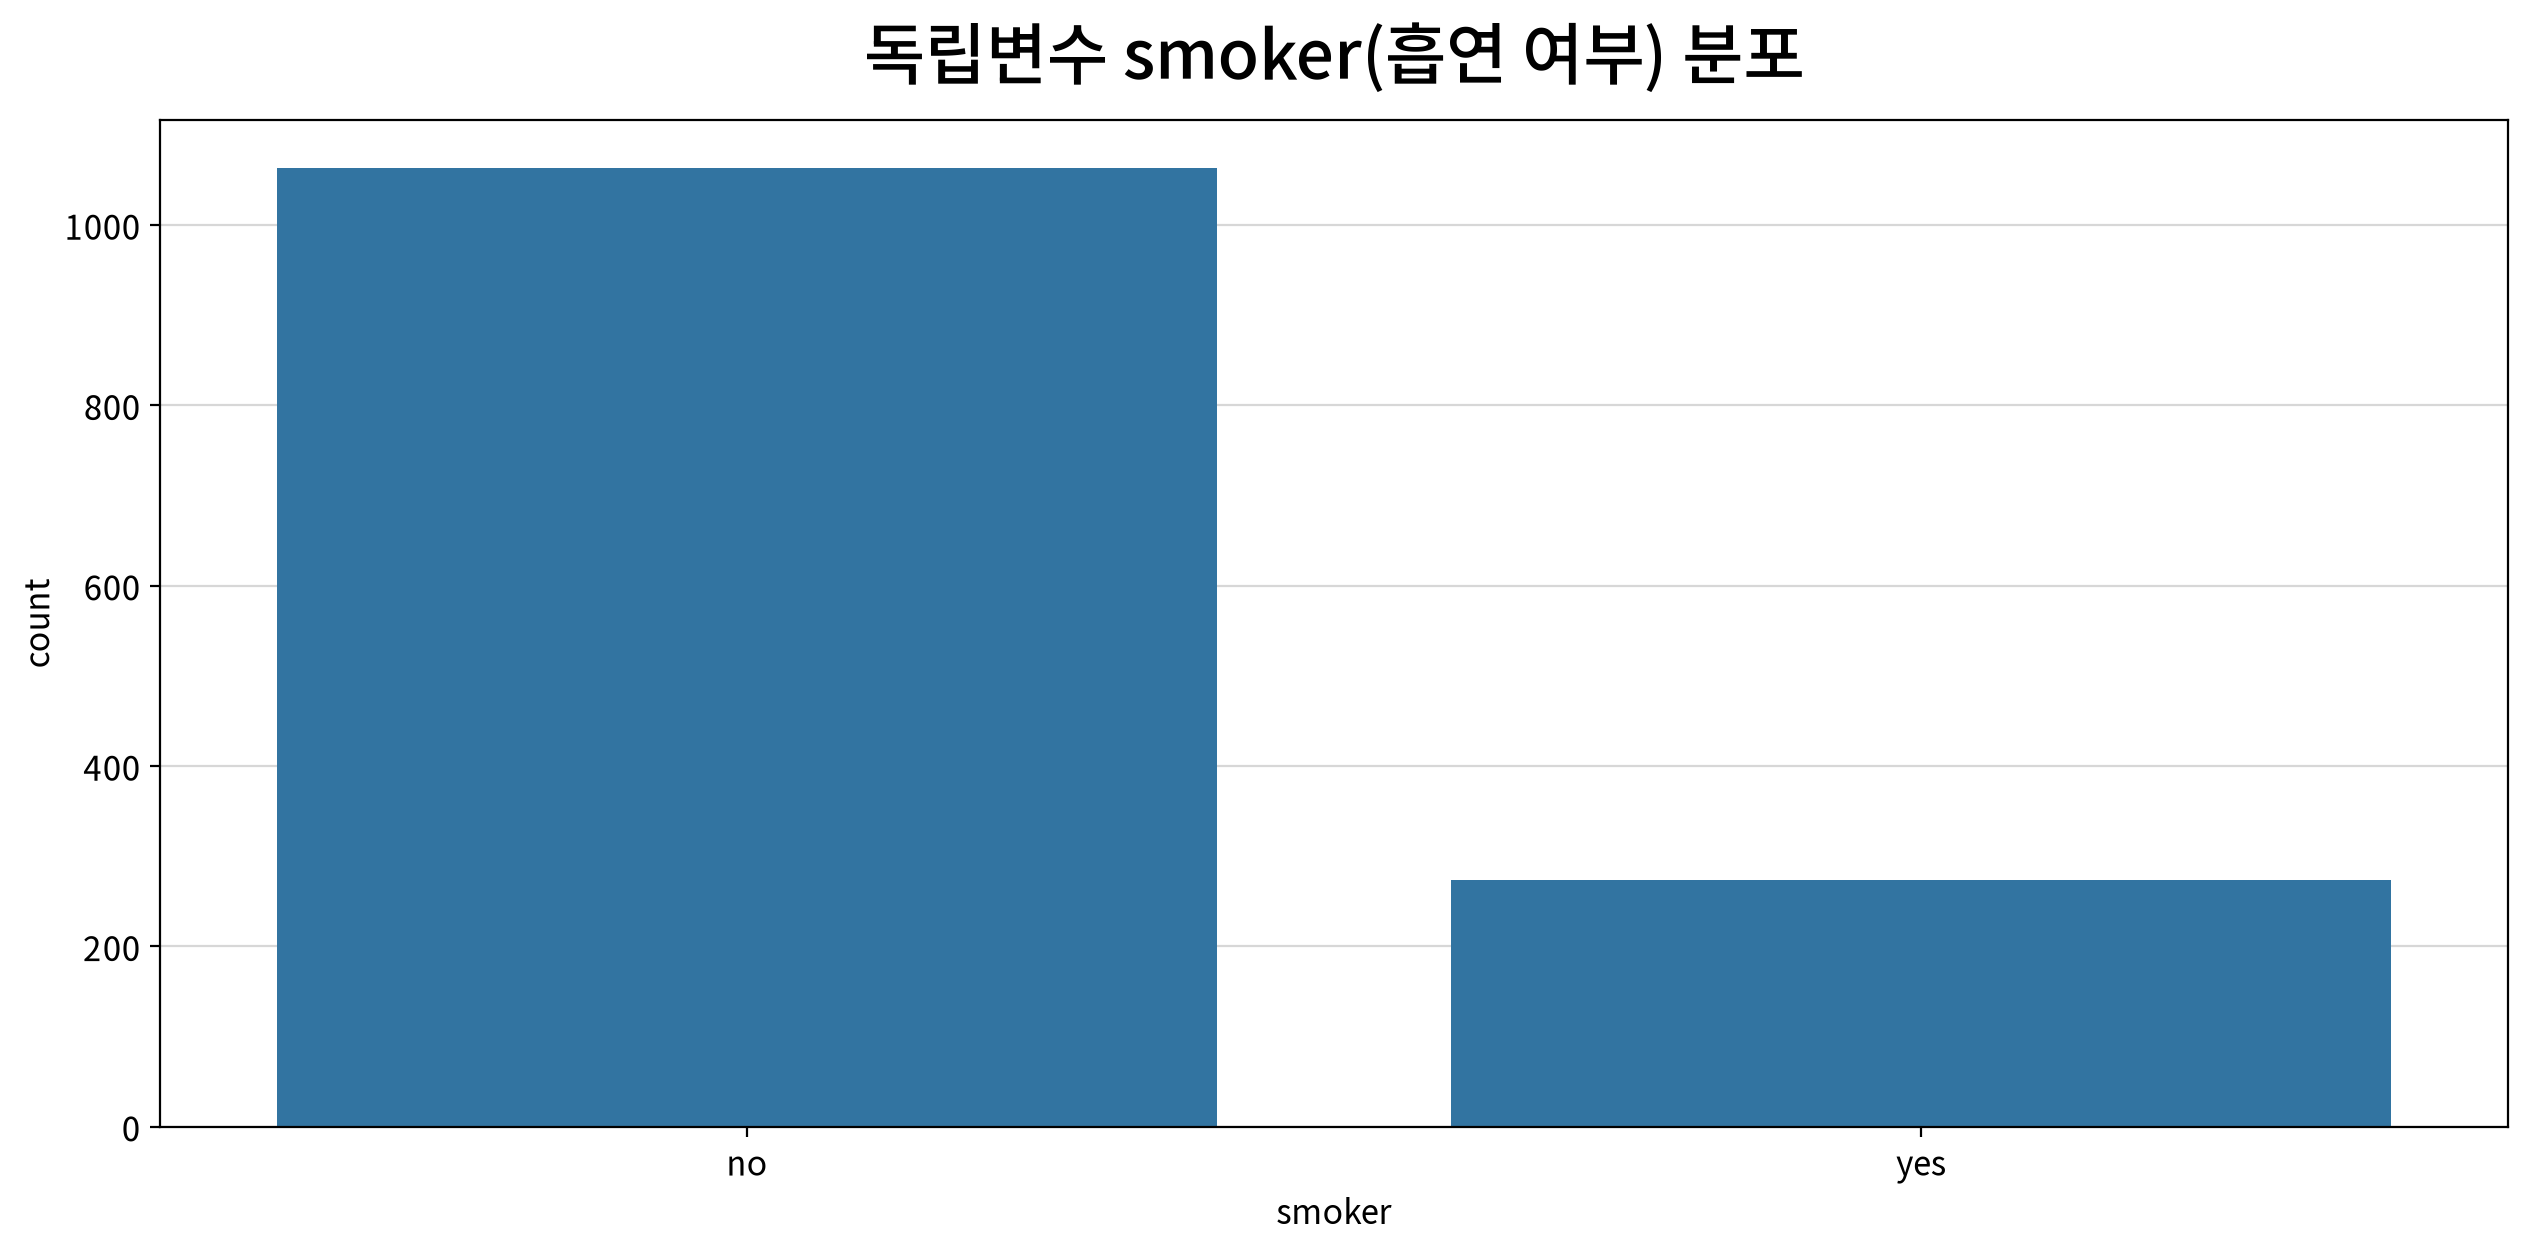

,count,unique,top,freq
smoker,1337,2,no,1063


,빈도,비율
smoker,,
no,1063,0.795
yes,274,0.205


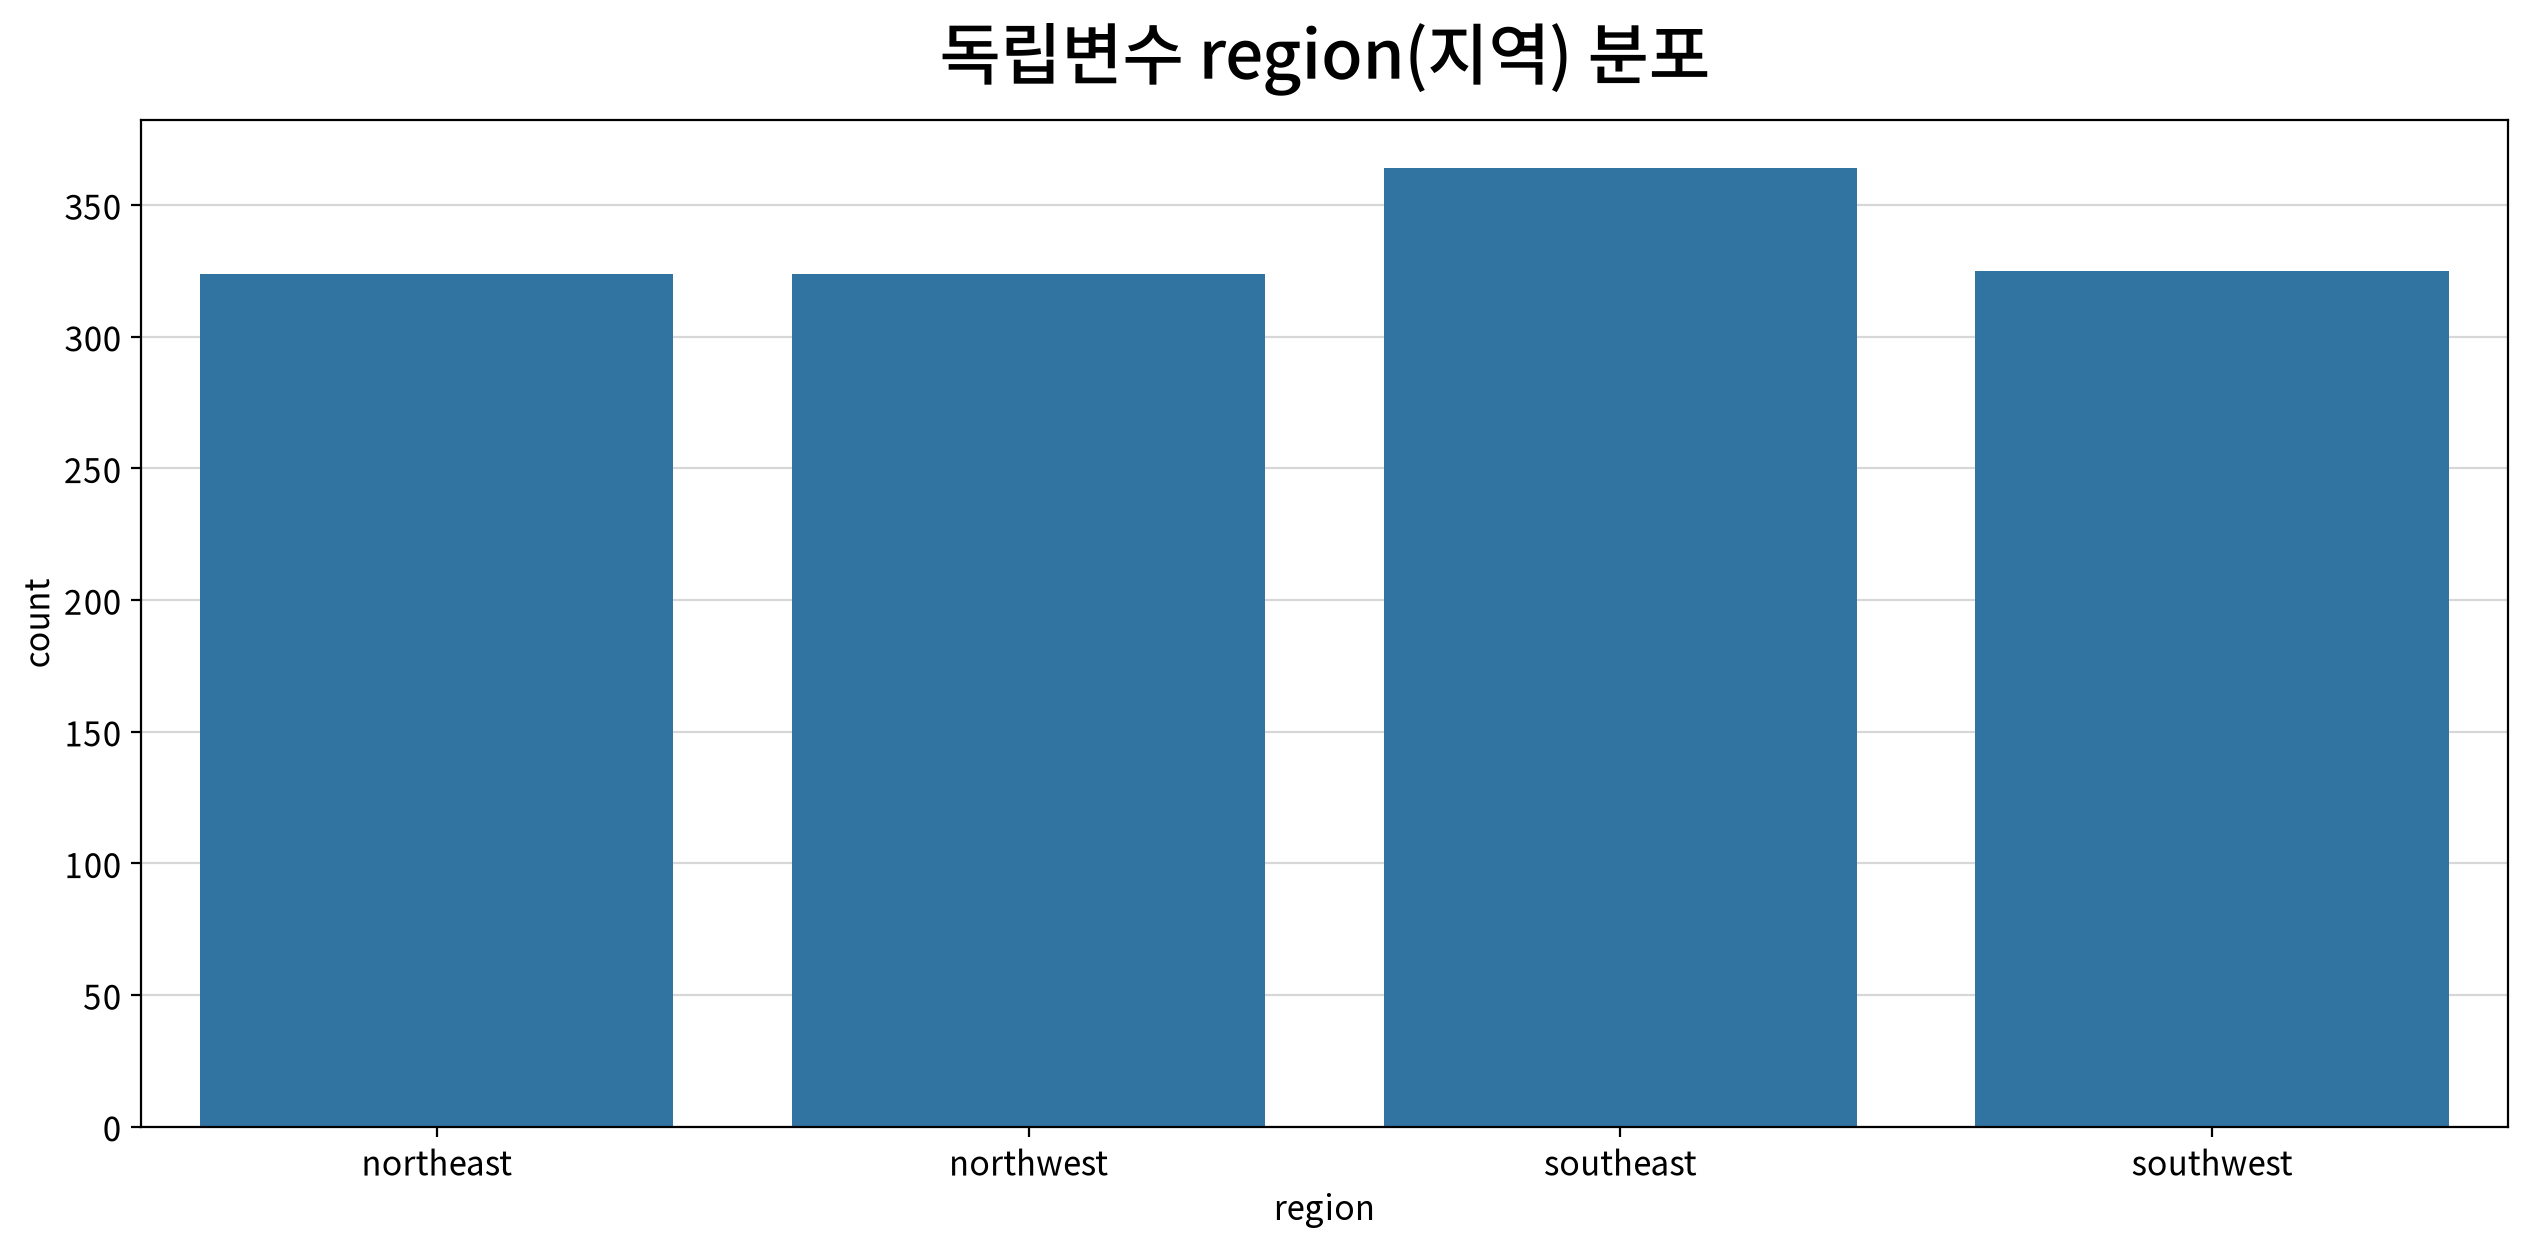

,count,unique,top,freq
region,1337,4,southeast,364


,빈도,비율
region,,
southeast,364,0.272
southwest,325,0.243
northeast,324,0.242
northwest,324,0.242


In [13]:
# 명목형 독립변수
for n in nominal_cols1:
    # 명목형 분포는 카운트 플롯으로 처리한다.
    my_plot.countplot(data=df2, x=n, title=f"독립변수 {n}({column_means1[n]}) 분포")

    # 명목형 기술통계량
    display(cat_desc1[[n]].T)

    # 추가적으로 빈도표 생성
    freq = df2[n].value_counts().rename("빈도").to_frame()
    # value_counts(normalize=True)
    # --> 전체 고유값의 개수(빈도수) 대신 전체 데이터의 비율을 계산
    freq["비율"] = df2[n].value_counts(normalize=True)
    display(freq)

> 명목형은 왜도 대신 **범주의 균형/불균형**과 **범주 수(→ 짝이 되는 검정)**를 점검한다.
> 수치는 함께 출력된 **빈도표** 기준이다.

| 변수 | 범주 수 | 빈도(비율) | 균형 여부 | 판단·짝 검정 |
|---|---|---|---|---|
| `sex`(성별) | 2 | male 675(50.5%) / female 662(49.5%) | **균형** | 2집단 → `charges`와 **T검정** |
| `smoker`(흡연여부) | 2 | no 1,063(79.5%) / yes 274(20.5%) | 불균형(흡연 소수) | 2집단 → **T검정**(흡연 274건이라 검정력은 충분) |
| `region`(거주 지역) | 4 | southeast 364(27.2%) / southwest 325(24.3%) / northeast 324(24.2%) / northwest 324(24.2%) | 대체로 균형 | **4집단 → ANOVA** |

**판단·조치**
- 범주 수에 따라 검정을 짝짓는다: **2집단은 T검정**(`sex`, `smoker`), **3집단 이상은 ANOVA**(`region`).
- 모든 범주가 검정 가능한 표본을 확보했으므로 **버릴 변수 없음**.
- `smoker`는 비율상 불균형이지만 소수 집단(흡연)이 종속변수의 **2차 봉우리(고비용 집단)**를 설명할 유력 후보이므로 반드시 유지한다.
- `region`은 각 범주가 비슷한 크기라 ANOVA의 **등분산·표본 균형 조건에 유리**하다.